# EDA từ raw hiện tại — Online Retail

## Mục lục

0. [Bối cảnh và câu hỏi](#0.-Bối-cảnh-và-câu-hỏi)
1. [Nguồn và kiểm kê](#1.-Nguồn-và-kiểm-kê)
2. [Chất lượng dữ liệu](#2.-Chất-lượng-dữ-liệu)
3. [Thống kê mô tả](#3.-Thống-kê-mô-tả)
4. [Phân tích đơn biến](#4.-Phân-tích-đơn-biến)
5. [Thời gian và khách hàng](#5.-Thời-gian-và-khách-hàng)
6. [Hai biến và đa biến](#6.-Hai-biến-và-đa-biến)
7. [Tương quan](#7.-Tương-quan)
8. [Phương án sau EDA](#8.-Phương-án-sau-EDA)
9. [Xuất kết quả và kiểm tra](#9.-Xuất-kết-quả-và-kiểm-tra)

**Chạy:** chọn kernel theo [README](README.md), **Restart Kernel → Run All**.
Raw duy nhất của dự án là `data/raw/Online Retail.xlsx`; các số liệu/nhận xét bên dưới
được tính từ file này. Các sản phẩm từ dữ liệu từng chọn nhầm không hợp lệ cho dự án.

## 0. Bối cảnh và câu hỏi

Phân cụm khách hàng không giám sát cần hiểu giao dịch trước khi chọn cách xử lý và biến hành vi.
Một **dòng raw** là dòng hàng/chứng từ; **InvoiceNo** nhóm nhiều dòng; **CustomerID** nhóm nhiều hóa đơn.
Không xem mã định danh như biến số liên tục; không coi khách thiếu mã là một khách thật.

Các câu hỏi: (1) thiếu/trùng/bất thường ở đâu; (2) giao dịch phân bố theo thời gian, lượng và giá ra sao;
(3) hành vi giữa khách khác nhau thế nào; (4) các biến liên hệ ra sao; (5) nhóm cần so sánh phương án xử lý nào?

Chỉ dùng raw hiện tại. Bản sao và tổng hợp trong bộ nhớ phục vụ EDA; không tạo dữ liệu sạch/feature chính thức,
không fit encoder/scaler, không huấn luyện mô hình. Múi giờ nguồn chưa được cung cấp.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image

# Works from the repository root, project/, or this notebook's directory.
project = next(candidate for parent in [Path.cwd(), *Path.cwd().parents]
               for candidate in [parent / "project", parent]
               if (candidate / "data/raw/Online Retail.xlsx").is_file())
module_dir = project / "notebooks/01_eda"
sys.path.insert(0, str(module_dir))
from eda_raw_analysis import load_analysis, make_figure, export_results, md_table, table_sheet, PURCHASE_RULE

analysis = load_analysis(project)

def show_table(name, limit=12):
    frame = analysis["tables"][name]
    display(Markdown(f"**{name}** — {len(frame):,} dòng × {len(frame.columns)} cột; sheet {table_sheet(analysis, name)} trong workbook kết quả."))
    view = frame.head(limit).copy()
    numeric_columns = view.select_dtypes(include="number").columns
    view[numeric_columns] = view[numeric_columns].round(4)
    display(view)

def show_figure(key):
    path, comment = make_figure(analysis, key)
    display(Image(filename=str(path), width=1000))
    display(Markdown(comment))
    record = next(row for row in analysis["figures"] if row["figure_id"] == key)
    names = ", ".join(f"{name} ({table_sheet(analysis, name)})"
                      for name in record["source_tables"].split(";"))
    display(Markdown("Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): " + names))

raw = analysis["df"]
customers = analysis["customers"]
display(Markdown(
    f"**Kết quả tính hiện tại:** {len(raw):,} dòng raw, "
    f"{raw.InvoiceNo.nunique():,} chứng từ, {raw.CustomerID.nunique():,} mã khách. "
    f"Thiếu CustomerID: {raw.CustomerID.isna().sum():,} dòng ({raw.CustomerID.isna().mean():.2%}). "
    f"Tập mua khảo sát: {len(analysis['purchase']):,} dòng/{len(customers):,} khách; "
    f"{customers.n_invoices.eq(1).mean():.2%} khách có một hóa đơn."))

**Kết quả tính hiện tại:** 541,909 dòng raw, 25,900 chứng từ, 4,372 mã khách. Thiếu CustomerID: 135,080 dòng (24.93%). Tập mua khảo sát: 397,884 dòng/4,338 khách; 34.42% khách có một hóa đơn.

## 1. Nguồn và kiểm kê

Nguồn mô tả: [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), đã đọc ngày 05/11/2026.
GBP dựa trên mô tả UCI, chưa có khai báo tiền tệ trong workbook. Các con số đo trực tiếp từ file local;
khớp cấu trúc không đủ chứng minh chuỗi tải file. [Kiểm kê nguồn](../../reports/kiem_ke_eda_raw_moi.md)
ghi file raw duy nhất, phạm vi và giới hạn tái lập.

In [2]:
show_table("raw_inventory", limit=30)

**raw_inventory** — 15 dòng × 2 cột; sheet T02 trong workbook kết quả.

,item,value
0,raw_file,data/raw/Online Retail.xlsx
1,sha256,43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93...
2,size_bytes,23715344
3,format,XLSX
4,sheet,Online Retail
5,rows,541909
6,columns,8
7,date_min,2010-12-01 08:26:00
8,date_max,2011-12-09 12:50:00
9,source_timezone,Không được cung cấp; không chuyển múi giờ


In [3]:
show_table("workbook_sheets", limit=12)

**workbook_sheets** — 1 dòng × 6 cột; sheet T01 trong workbook kết quả.

,sheet,rows,columns,column_names,all_blank_rows,repeated_header_rows
0,Online Retail,541909,8,InvoiceNo | StockCode | Description | Quantity...,0,0


In [4]:
show_table("data_dictionary", limit=12)

**data_dictionary** — 8 dòng × 6 cột; sheet T03 trong workbook kết quả.

,column,raw_dtype,eda_dtype,meaning,role,unit
0,InvoiceNo,object,string,Mã chứng từ; C là dấu hiệu hủy theo UCI,identifier,mã
1,StockCode,object,string,Mã hàng; có thể gồm mã dịch vụ/điều chỉnh,identifier/category,mã
2,Description,object,string,Mô tả hàng,text,văn bản
3,Quantity,int64,int64,"Số lượng trên dòng, có dấu",measure,đơn vị hàng
4,InvoiceDate,datetime64[us],datetime64[us],"Thời điểm chứng từ, chưa biết múi giờ",datetime,thời gian nguồn
5,UnitPrice,float64,float64,Đơn giá theo mô tả UCI,measure,GBP/đơn vị
6,CustomerID,float64,string,Mã khách; không phải biến số liên tục,identifier,mã
7,Country,str,string,Quốc gia của khách theo UCI,category,nhãn


In [5]:
show_table("column_mapping", limit=12)

**column_mapping** — 8 dòng × 4 cột; sheet T04 trong workbook kết quả.

,ten_trong_api_chua_tuong_thich,current_raw_column,eda_column,action
0,Invoice,InvoiceNo,InvoiceNo,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
1,StockCode,StockCode,StockCode,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
2,Description,Description,Description,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
3,Quantity,Quantity,Quantity,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
4,InvoiceDate,InvoiceDate,InvoiceDate,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
5,Price,UnitPrice,UnitPrice,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
6,Customer ID,CustomerID,CustomerID,"Đối chiếu API hiện có; chỉ có một raw, không đ..."
7,Country,Country,Country,"Đối chiếu API hiện có; chỉ có một raw, không đ..."


In [6]:
show_table("raw_samples", limit=12)

**raw_samples** — 10 dòng × 10 cột; sheet T05 trong workbook kết quả.

,zero_based_row,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,sample
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,head
1,1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,head
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,head
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,head
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,head
5,541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,tail
6,541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,tail
7,541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,tail
8,541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,tail
9,541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,tail


## 2. Chất lượng dữ liệu

Các vấn đề có thể chồng lấn. **Không cộng số dòng, chứng từ hay khách của các nhóm như nhóm độc lập.**
Trùng InvoiceNo+StockCode không mặc nhiên trùng giao dịch. C là dấu hiệu chứng từ hủy;
không thay thế quy trình ghép trả hàng với đơn gốc. Ngưỡng IQR chỉ gắn cờ khảo sát.

In [7]:
show_table("missing_values", limit=12)

**missing_values** — 8 dòng × 5 cột; sheet T06 trong workbook kết quả.

,column,raw_null_count,empty_or_whitespace,eda_missing_count,eda_missing_pct
0,InvoiceNo,0,0,0,0.0000
1,StockCode,0,0,0,0.0000
2,Description,1454,0,1454,0.2683
3,Quantity,0,0,0,0.0000
4,InvoiceDate,0,0,0,0.0000
5,UnitPrice,0,0,0,0.0000
6,CustomerID,135080,0,135080,24.9267
7,Country,0,0,0,0.0000


In [8]:
show_table("quality_issues", limit=30)

**quality_issues** — 14 dòng × 10 cột; sheet T07 trong workbook kết quả.

,issue,rows,pct_rows,invoices,known_customers,signed_value,absolute_value,rows_missing_customer,rows_zero_price,note
0,missing_customer,135080,24.9267,3710,0,1447682.12,2062871.16,135080,2475,Các nhóm chồng lấn; không cộng
1,missing_description,1454,0.2683,1454,0,0.00,0.00,1454,1454,Các nhóm chồng lấn; không cộng
2,exact_duplicate_extra,5268,0.9721,1933,960,21740.98,27406.50,43,5,Các nhóm chồng lấn; không cộng
3,all_rows_in_duplicate_groups,10147,1.8725,1933,960,41755.54,53021.78,85,10,Các nhóm chồng lấn; không cộng
4,C_prefix,9288,1.7139,3836,1589,-896812.49,896812.49,383,0,Các nhóm chồng lấn; không cộng
5,quantity_negative,10624,1.9605,5172,1589,-896812.49,896812.49,1719,1336,Các nhóm chồng lấn; không cộng
6,quantity_zero,0,0.0000,0,0,0.00,0.00,0,0,Các nhóm chồng lấn; không cộng
7,price_negative,2,0.0004,2,0,-22124.12,22124.12,2,0,Các nhóm chồng lấn; không cộng
8,price_zero,2515,0.4641,2155,31,0.00,0.00,2475,2515,Các nhóm chồng lấn; không cộng
9,missing_invoice,0,0.0000,0,0,0.00,0.00,0,0,Các nhóm chồng lấn; không cộng


In [9]:
show_table("duplicate_criteria", limit=12)

**duplicate_criteria** — 3 dòng × 3 cột; sheet T08 trong workbook kết quả.

,criterion,rows,interpretation
0,"8 cột raw, dòng dư sau lần đầu",5268,Không tự xóa
1,"8 cột raw, mọi dòng thuộc nhóm trùng",10147,Chồng lấn với dòng dư
2,"InvoiceNo + StockCode, dòng dư",10684,Không phải khóa dòng; có thể nhiều lần thêm hà...


In [10]:
show_table("duplicate_samples", limit=12)

**duplicate_samples** — 16 dòng × 9 cột; sheet T09 trong workbook kết quả.

,zero_based_row,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
1,489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
2,494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
3,517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
4,521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
5,527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
6,537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
7,539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
8,548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
9,555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [11]:
show_table("document_status", limit=12)

**document_status** — 2 dòng × 4 cột; sheet T11 trong workbook kết quả.

,rows,invoices,customers,signed_value
document_type,,,,
C-prefix,9288,3836,1589,-8.968125e+05
Non-C,532621,22064,4339,1.064456e+07


In [12]:
show_table("invoice_prefixes", limit=12)

**invoice_prefixes** — 3 dòng × 2 cột; sheet T12 trong workbook kết quả.

,rows,invoices
prefix,,
A,3,3
C,9288,3836
numeric,532618,22061


In [13]:
show_table("document_quantity_counts", limit=12)

**document_quantity_counts** — 2 dòng × 4 cột; sheet T10 trong workbook kết quả.

quantity_sign,negative,zero,positive,missing
document_type,,,,
Non-C,1336,0,531285,0
C-prefix,9288,0,0,0


In [14]:
show_table("price_sign_counts", limit=12)

**price_sign_counts** — 3 dòng × 3 cột; sheet T13 trong workbook kết quả.

,rows,invoices,customers
price_sign,,,
negative,2,2,0
positive,539392,23796,4371
zero,2515,2155,31


In [15]:
show_table("negative_price_samples", limit=12)

**negative_price_samples** — 2 dòng × 8 cột; sheet T15 trong workbook kết quả.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom


In [16]:
show_table("nonpositive_price_samples", limit=12)

**nonpositive_price_samples** — 12 dòng × 8 cột; sheet T14 trong workbook kết quả.

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,<NA>,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom
1970,536545,21134,<NA>,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom
1971,536546,22145,<NA>,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1972,536547,37509,<NA>,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1987,536549,85226A,<NA>,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
1988,536550,85044,<NA>,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2024,536552,20950,<NA>,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
2025,536553,37461,<NA>,3,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2026,536554,84670,<NA>,23,2010-12-01 14:35:00,0.0,<NA>,United Kingdom
2406,536589,21777,<NA>,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom


In [17]:
show_table("identifier_conflicts", limit=12)

**identifier_conflicts** — 6 dòng × 6 cột; sheet T16 trong workbook kết quả.

,key,attribute,keys_with_value,keys_multiple_values,maximum_values,note
0,InvoiceNo,CustomerID,25900,0,1,Dấu hiệu cần xem xét; không mặc định là lỗi
1,InvoiceNo,Country,25900,0,1,Dấu hiệu cần xem xét; không mặc định là lỗi
2,InvoiceNo,InvoiceDate,25900,43,2,Dấu hiệu cần xem xét; không mặc định là lỗi
3,CustomerID,Country,4372,8,2,Dấu hiệu cần xem xét; không mặc định là lỗi
4,StockCode,Description,4070,650,8,Dấu hiệu cần xem xét; không mặc định là lỗi
5,Description,StockCode,4223,172,146,Dấu hiệu cần xem xét; không mặc định là lỗi


In [18]:
show_table("invoice_conflict_samples", limit=12)

**invoice_conflict_samples** — 20 dòng × 4 cột; sheet T17 trong workbook kết quả.

,rows,customers,countries,timestamps
InvoiceNo,,,,
536591,40,1,1,2
540185,29,1,1,2
541596,103,1,1,2
541631,72,1,1,2
541809,91,0,1,2
541816,73,1,1,2
541849,49,1,1,2
542217,18,1,1,2
542806,39,1,1,2


In [19]:
show_table("stock_description_audit", limit=12)

**stock_description_audit** — 4,070 dòng × 3 cột; sheet T18 trong workbook kết quả.

,rows,n_descriptions,missing_description
StockCode,,,
20713,684,8,4
23084,1067,7,10
85175,154,6,1
21830,112,6,2
21181,882,5,2
23343,501,5,0
23131,122,5,1
72807A,118,5,0
85172,53,5,0


In [20]:
show_table("nonstandard_stock_codes", limit=12)

**nonstandard_stock_codes** — 33 dòng × 2 cột; sheet T19 trong workbook kết quả.

,rows,signed_value
StockCode,,
POST,1256,66230.640
DOT,710,206245.480
M,571,-68674.190
C2,144,6986.000
D,77,-5696.220
S,63,-3049.390
BANK CHARGES,37,-7175.639
AMAZONFEE,34,-221520.500
CRUK,16,-7933.430


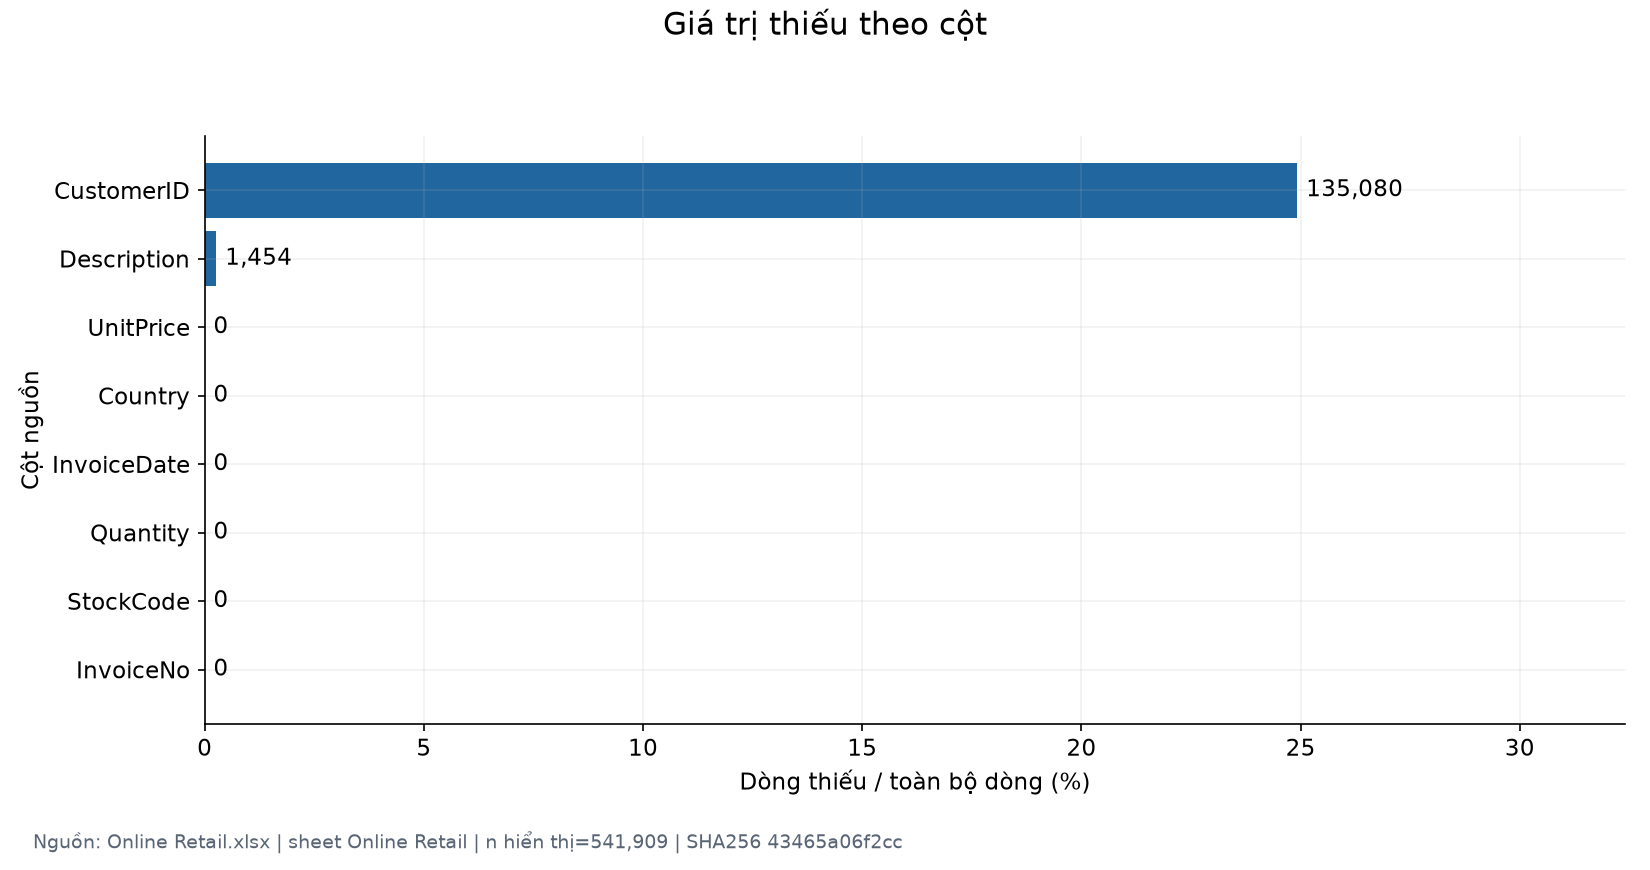

**Phạm vi:** Toàn bộ raw

**Quan sát:** Thiếu mã khách làm giảm phạm vi có thể tổng hợp hành vi theo khách.

**Bằng chứng:** CustomerID thiếu 135,080/541,909 dòng (24.93%); giá trị có dấu của nhóm này 1,447,682.12 GBP.

**Ý nghĩa:** Cần giữ thống kê giao dịch vô danh riêng với phân tích khách có mã.

**Giới hạn / câu hỏi tiếp:** Không suy ra danh tính khách thiếu, không coi mọi dòng vô danh là một khách; giá trị có dấu chưa là doanh thu thuần.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): missing_values (T06), customer_coverage (T40)

In [21]:
show_figure("missing_values")

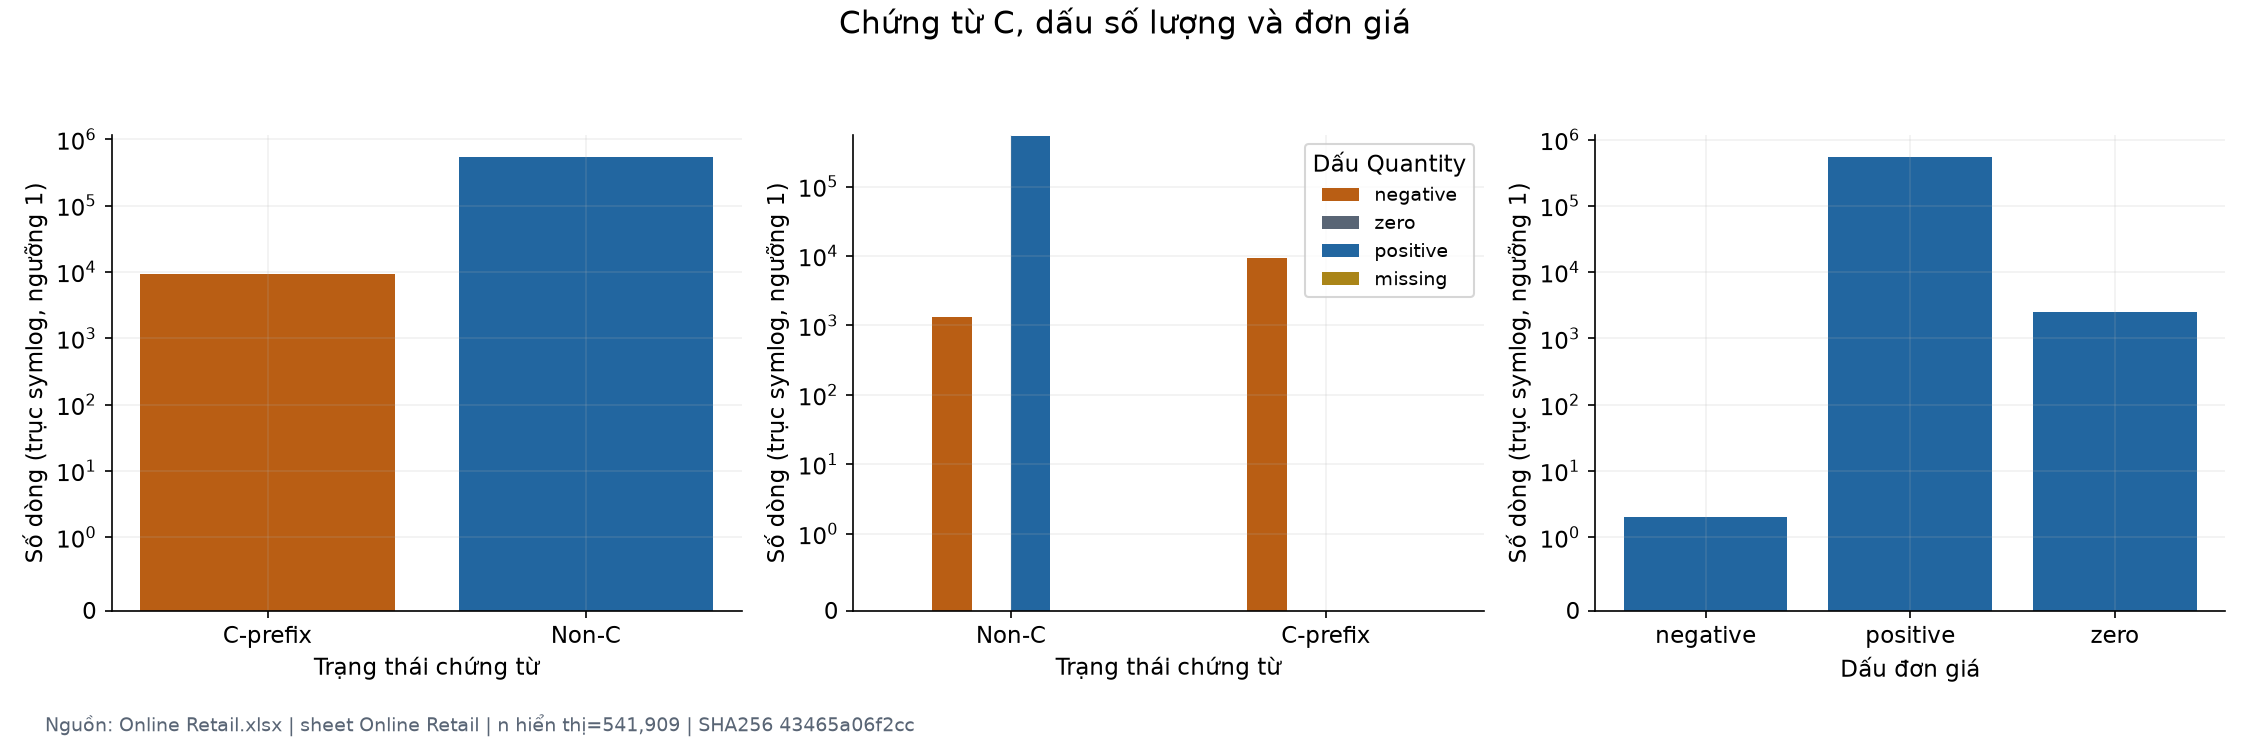

**Phạm vi:** Toàn bộ raw

**Quan sát:** Cần phân biệt dấu số lượng với dấu hiệu chứng từ hủy.

**Bằng chứng:** C: 9,288 dòng/3,836 chứng từ; Q âm không C: 1,336; giá âm 2, giá 0 2,515 dòng.

**Ý nghĩa:** Một quy tắc chỉ dựa vào tiền tố C có thể bỏ sót điều chỉnh khác.

**Giới hạn / câu hỏi tiếp:** Những nhóm này chồng lấn; C chưa được ghép với đơn gốc. Không tự kết luận giá 0 là quà tặng hay lỗi.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): document_status (T11), document_quantity_counts (T10), price_sign_counts (T13), negative_price_samples (T15)

In [22]:
show_figure("document_quantity_price")

## 3. Thống kê mô tả

Bảng số gồm count hữu hạn, min/max, mean/median, std mẫu, q1/q3, IQR, p95/p99, skew và số dòng ngoài IQR1.5.
Không tính trung bình CustomerID/InvoiceNo/StockCode. Tần suất đầy đủ và nhóm hiếm được xuất riêng.
Mẫu cực trị giúp kiểm tra ngữ cảnh; không kết luận mọi điểm lớn là lỗi.

In [23]:
show_table("numeric_summary", limit=20)

**numeric_summary** — 3 dòng × 18 cột; sheet T20 trong workbook kết quả.

,population,variable,count,missing_or_nonfinite,minimum,maximum,mean,median,std,q1,q3,iqr,p95,p99,skewness,iqr_lower,iqr_upper,outside_iqr
0,raw lines,Quantity,541909,0,-80995.00,80995.0,9.5522,3.00,218.0812,1.00,10.00,9.00,29.00,100.0,-0.2641,-12.50,23.50,58619
1,raw lines,UnitPrice,541909,0,-11062.06,38970.0,4.6111,2.08,96.7599,1.25,4.13,2.88,9.95,18.0,186.5070,-3.07,8.45,39627
2,raw lines,SignedLineValue,541909,0,-168469.60,168469.6,17.9878,9.75,378.8108,3.40,17.40,14.00,59.40,180.0,-0.9644,-17.60,38.40,44997


In [24]:
show_table("categorical_summary", limit=20)

**categorical_summary** — 5 dòng × 5 cột; sheet T26 trong workbook kết quả.

,variable,unique_nonmissing,missing,singleton_categories,categories_under_100_lines
0,InvoiceNo,25900,0,5841,25223
1,CustomerID,4372,135080,79,3257
2,StockCode,4070,0,233,2489
3,Description,4223,1454,308,2635
4,Country,38,0,0,9


In [25]:
show_table("extreme_samples", limit=20)

**extreme_samples** — 18 dòng × 12 cột; sheet T22 trong workbook kết quả.

,zero_based_row,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SignedLineValue,extreme_variable,extreme_kind
0,540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,-168469.60,Quantity,minimum
1,61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,-77183.60,Quantity,minimum
2,225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,<NA>,United Kingdom,-0.00,Quantity,minimum
3,540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,168469.60,Quantity,maximum
4,61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,77183.60,Quantity,maximum
5,502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256,United Kingdom,0.00,Quantity,maximum
6,299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom,-11062.06,UnitPrice,minimum
7,299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom,-11062.06,UnitPrice,minimum
8,622,536414,22139,<NA>,56,2010-12-01 11:52:00,0.00,<NA>,United Kingdom,0.00,UnitPrice,minimum
9,222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098,United Kingdom,-38970.00,UnitPrice,maximum


## 4. Phân tích đơn biến

Histogram toàn miền dùng sign(x)×ln(1+|x|), boxplot dùng trục symlog để giữ số âm/0/cực trị;
đây chỉ là tọa độ hiển thị. Không cắt hay bỏ quan sát; bảng mô tả vẫn ở đơn vị gốc.
Top danh mục xếp theo **số dòng**, có số dòng phần còn lại trong nhận xét.

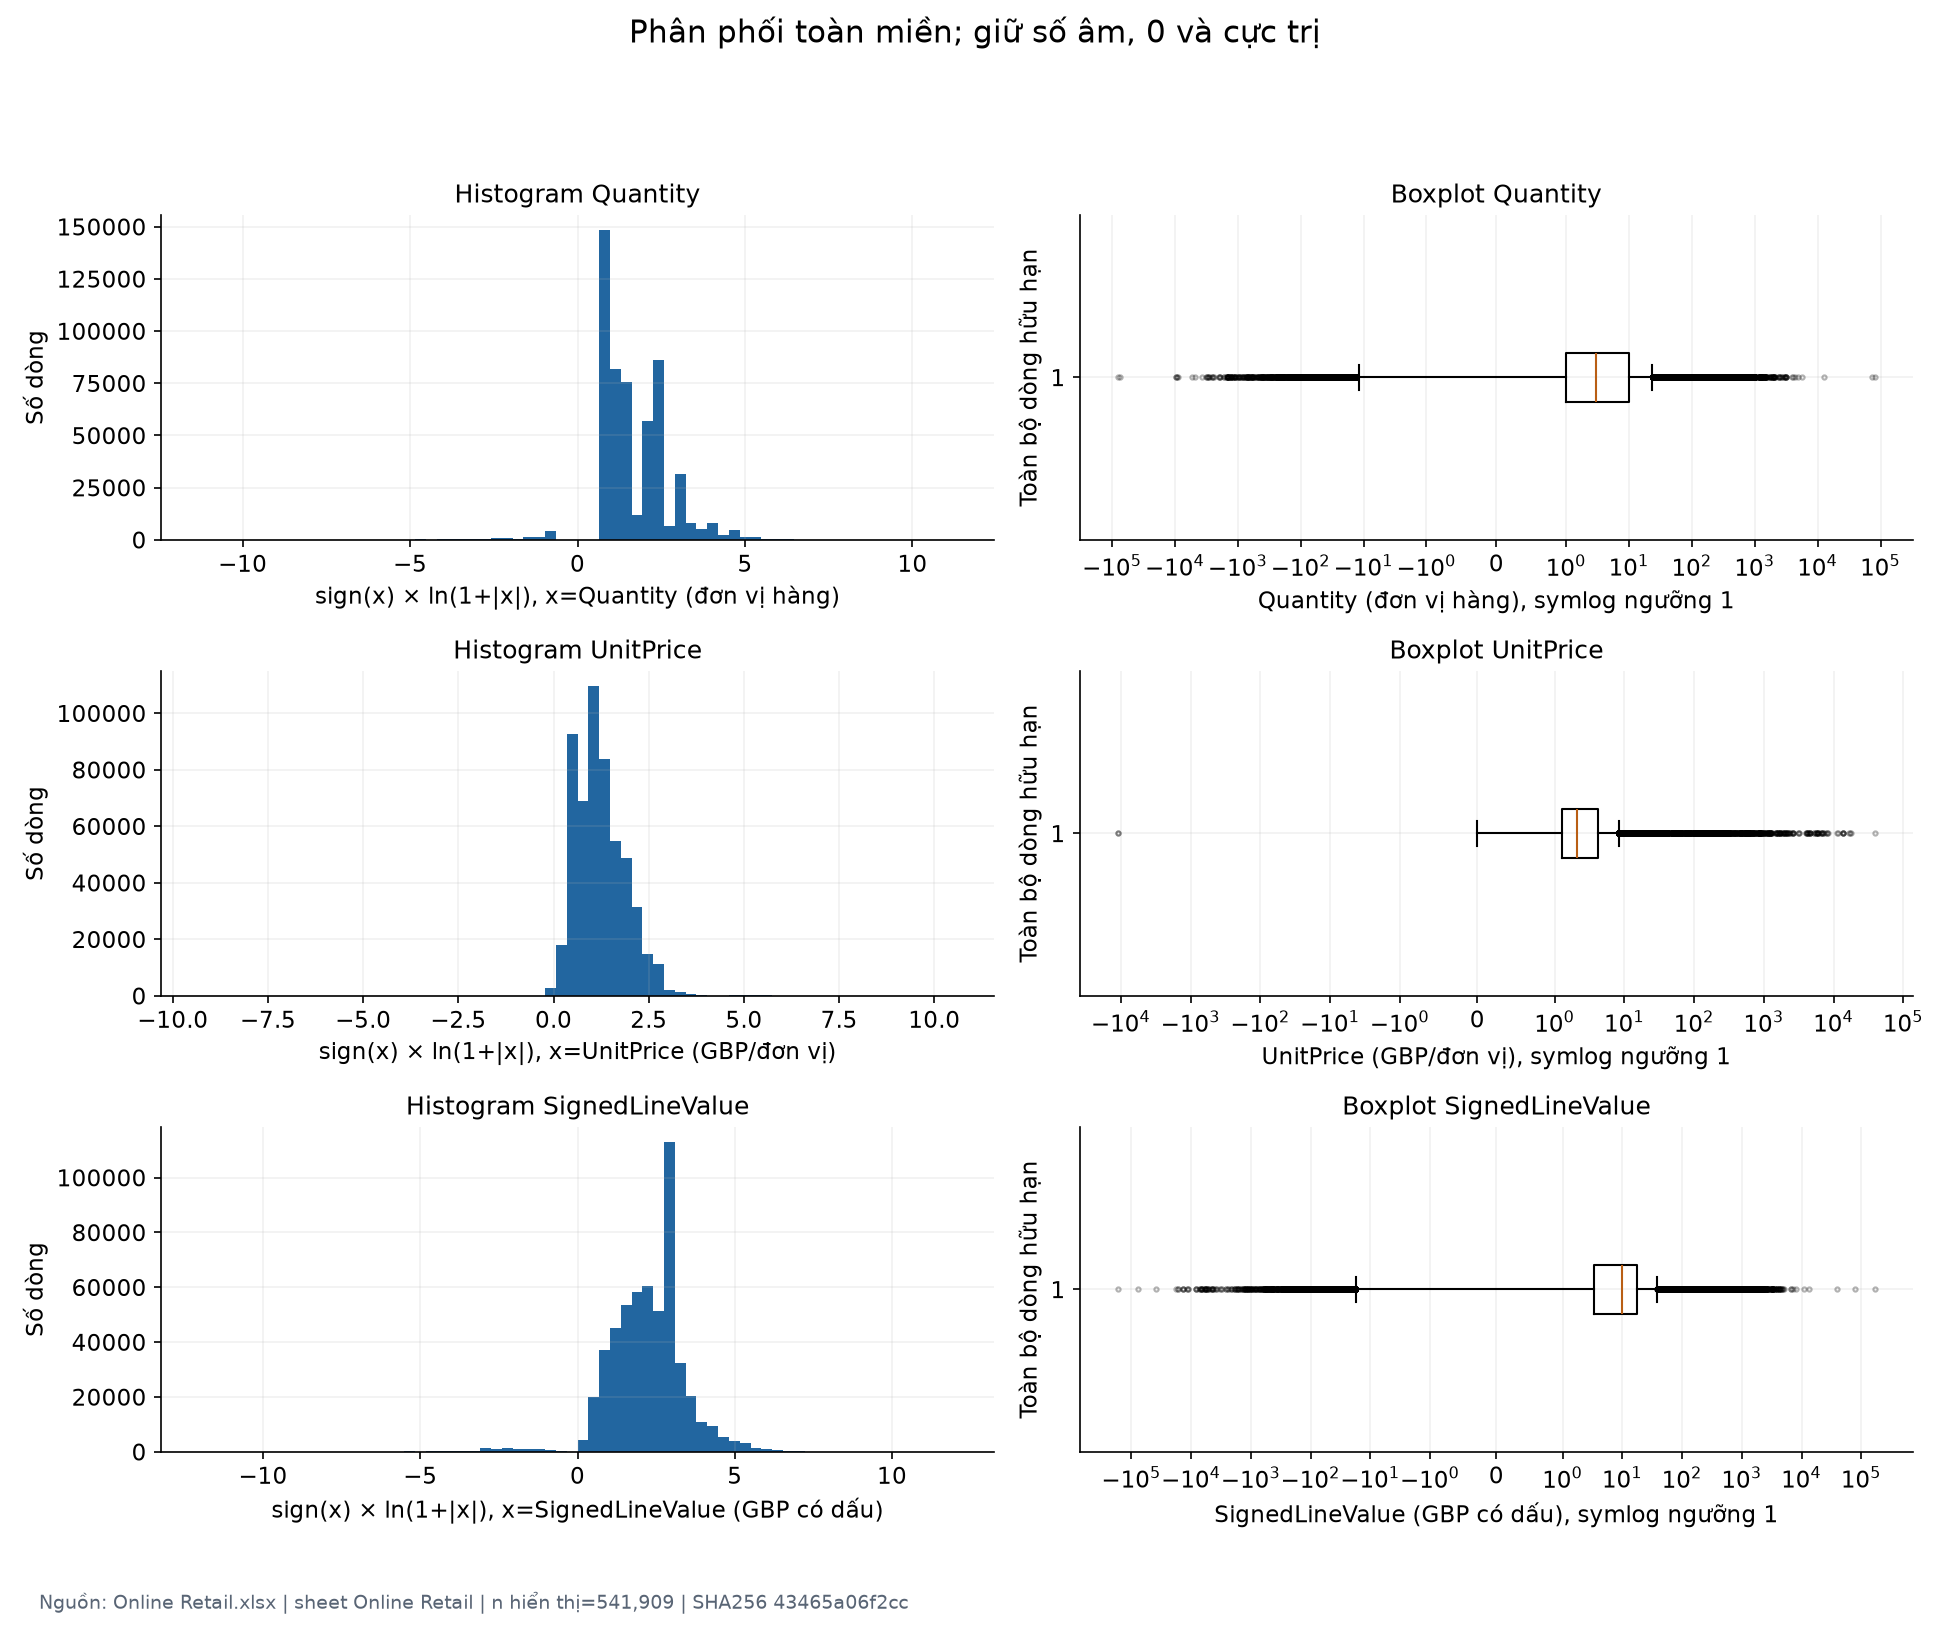

**Phạm vi:** Toàn bộ raw

**Quan sát:** Trung vị và cực trị cách xa nhau; cần xem phân vị trước khi chọn cách biến đổi.

**Bằng chứng:** Quantity: median=3.00, p99=100.00, min=-80,995.00, max=80,995.00; UnitPrice: median=2.08, p99=18.00, min=-11,062.06, max=38,970.00; SignedLineValue: median=9.75, p99=180.00, min=-168,469.60, max=168,469.60

**Ý nghĩa:** Độ nhạy của tổng giá trị và khoảng cách phân cụm với khách mua lớn cần được khảo sát.

**Giới hạn / câu hỏi tiếp:** Đổi tọa độ chỉ để hiển thị, không scale dữ liệu hay cắt quan sát. Ngoại lệ IQR là cờ kiểm tra; Q×P có phụ thuộc công thức và chưa là doanh thu thuần.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): numeric_summary (T20), extreme_samples (T22)

In [26]:
show_figure("raw_distributions")

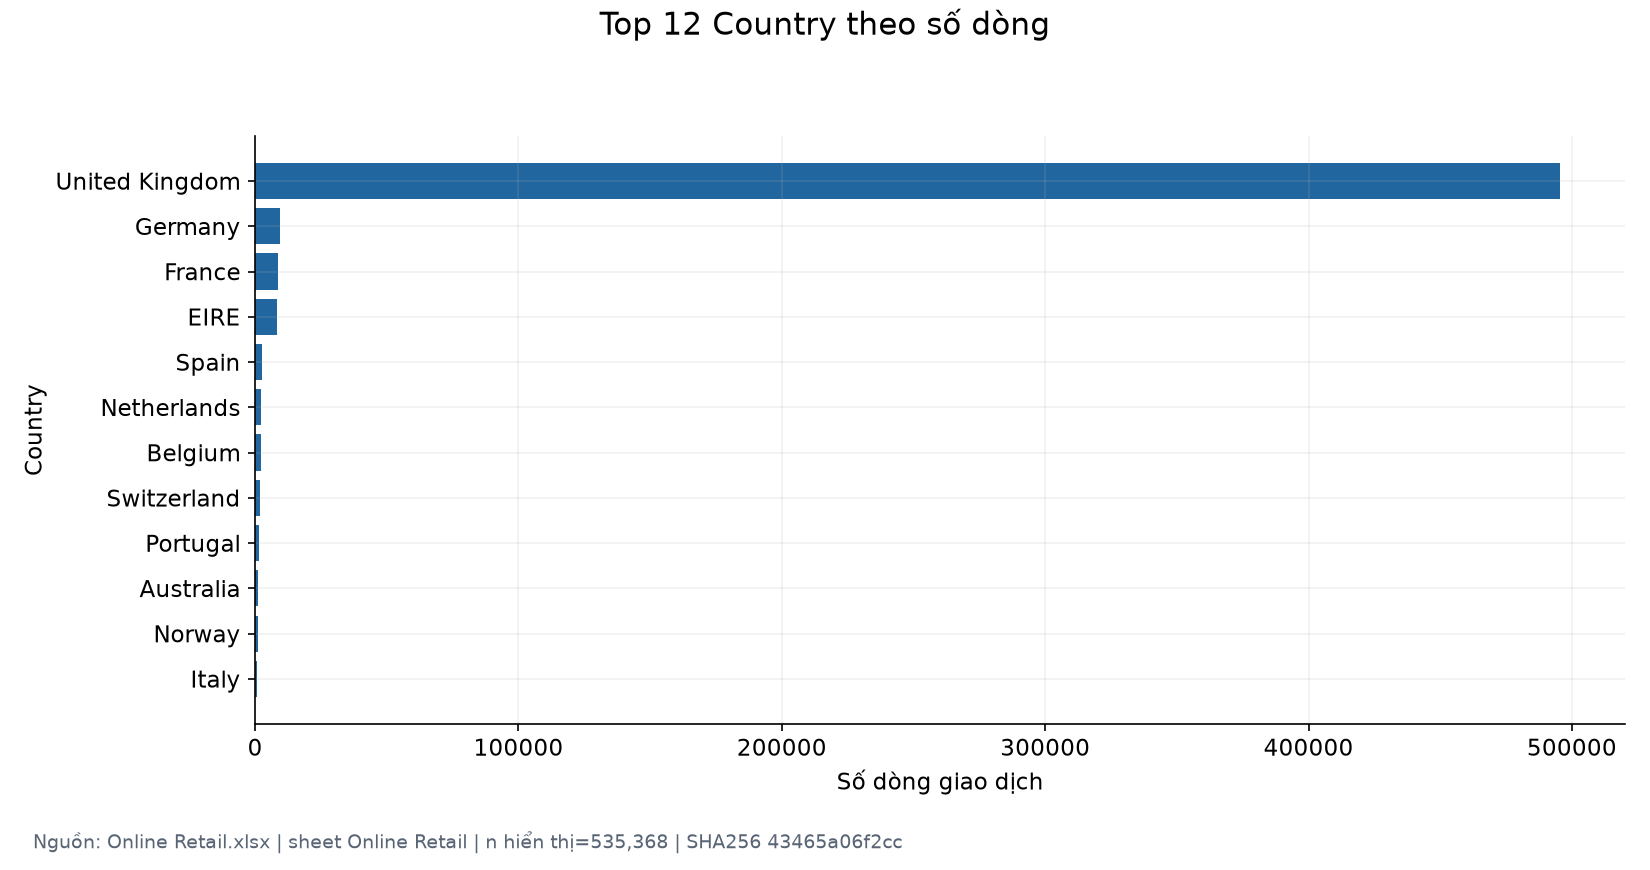

**Phạm vi:** Toàn bộ raw; hiển thị top 12 Country; phần còn lại 6,541 dòng

**Quan sát:** Nhóm nhiều dòng nhất là United Kingdom.

**Bằng chứng:** Nhóm đầu có 495,478 dòng (91.43% toàn raw); top 12 có 535,368/541,909 dòng; 38 giá trị khác nhau.

**Ý nghĩa:** Cần đánh giá mức tập trung khi đề xuất nhóm danh mục và tỷ lệ hành vi.

**Giới hạn / câu hỏi tiếp:** Xếp hạng số dòng không đồng nghĩa số sản phẩm bán, doanh số hay số khách. Nhãn quốc gia/mã hàng chưa được chuẩn hóa nghiệp vụ.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): country_counts (T23), categorical_summary (T26)

In [27]:
show_figure("country_counts")

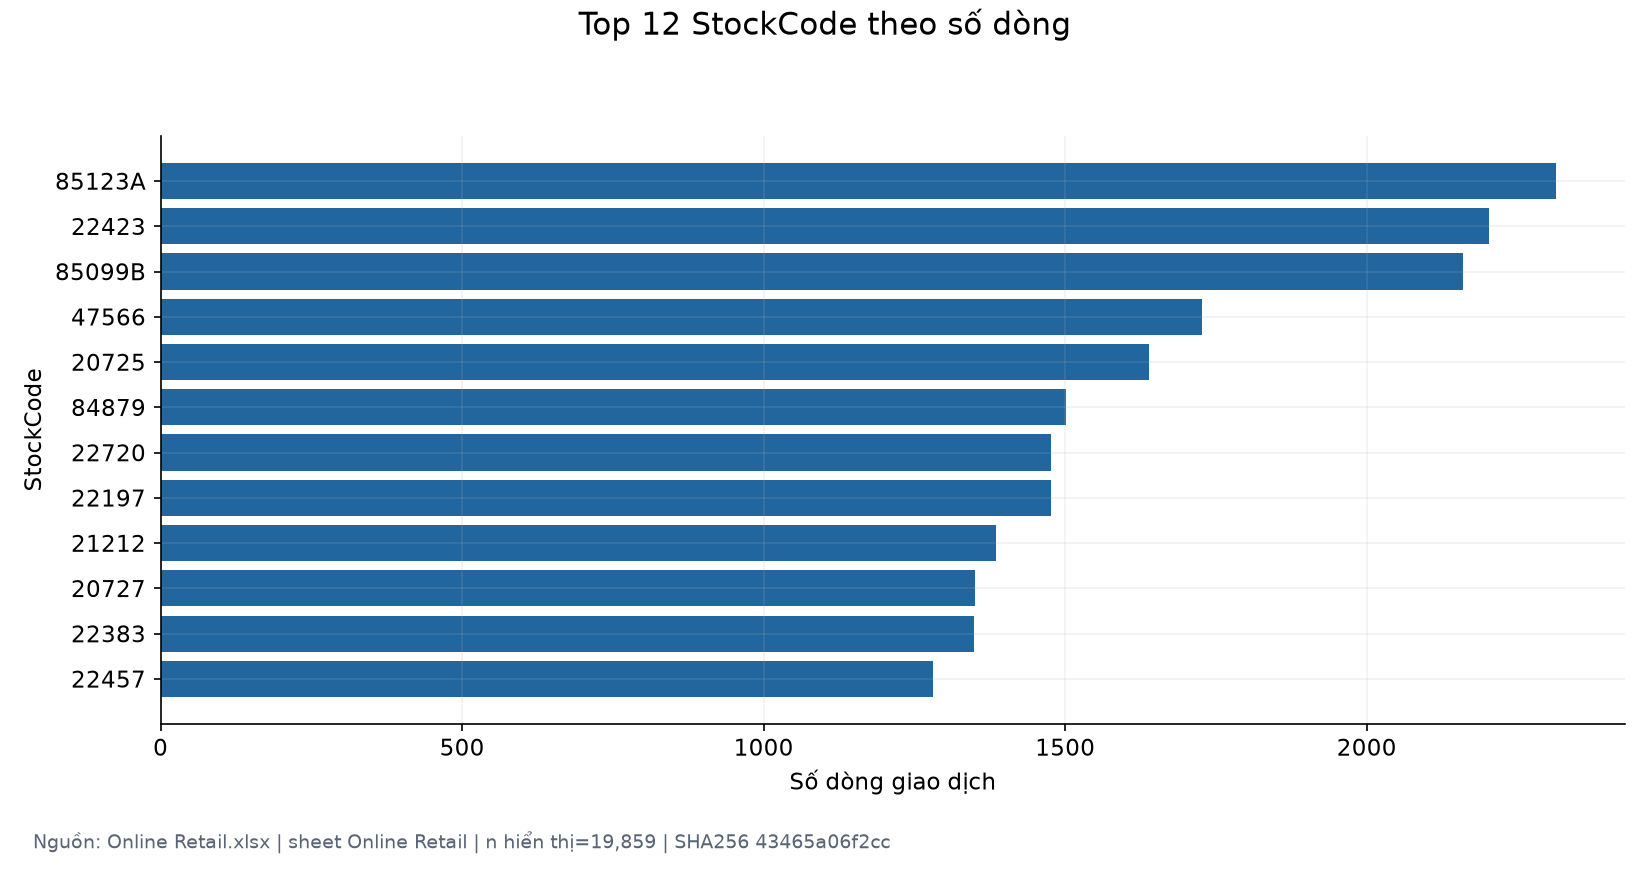

**Phạm vi:** Toàn bộ raw; hiển thị top 12 StockCode; phần còn lại 522,050 dòng

**Quan sát:** Nhóm nhiều dòng nhất là 85123A.

**Bằng chứng:** Nhóm đầu có 2,313 dòng (0.43% toàn raw); top 12 có 19,859/541,909 dòng; 4,070 giá trị khác nhau.

**Ý nghĩa:** Cần đánh giá mức tập trung khi đề xuất nhóm danh mục và tỷ lệ hành vi.

**Giới hạn / câu hỏi tiếp:** Xếp hạng số dòng không đồng nghĩa số sản phẩm bán, doanh số hay số khách. Nhãn quốc gia/mã hàng chưa được chuẩn hóa nghiệp vụ.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): stock_code_counts (T24), categorical_summary (T26)

In [28]:
show_figure("stock_code_counts")

## 5. Thời gian và khách hàng

Số dòng và số hóa đơn là hai đại lượng khác nhau. Tổng có dấu Q×P của raw chưa được gọi là doanh thu thuần.
Tháng biên cần đọc theo timestamp thực tế, đặc biệt tháng cuối chưa đầy đủ.

Phạm vi mua và mọi công thức dưới đây là **khảo sát tạm thời**. Giữ nguyên trùng/mã dịch vụ;
không gán quốc gia duy nhất cho khách có nhiều quốc gia. Không dùng ngày chạy để tính recency.

In [29]:
display(Markdown(PURCHASE_RULE))

InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean.

In [30]:
show_table("analysis_scopes", limit=20)

**analysis_scopes** — 4 dòng × 5 cột; sheet T39 trong workbook kết quả.

,scope,observations,invoices,customers,filter
0,raw,541909,25900.0,4372,"Toàn bộ dòng raw, không bỏ trùng"
1,temporary_purchase,397884,18532.0,4338,"InvoiceNo và CustomerID có mã, InvoiceDate hợp..."
2,customer,4338,18532.0,4338,Tổng hợp tạm; không xuất bộ feature khách
3,gap_defined,2845,NaN,2845,Khách có >=2 hóa đơn; không điền 0 cho khách m...


In [31]:
show_table("aggregation_formulas", limit=20)

**aggregation_formulas** — 10 dòng × 4 cột; sheet T38 trong workbook kết quả.

,variable,grain,formula,unit
0,SignedLineValue,raw,"Quantity * UnitPrice, không làm tròn",GBP có dấu
1,n_invoices,customer,nunique(InvoiceNo) trong tập mua tạm,hóa đơn/khách
2,monetary,customer,sum(Quantity * UnitPrice) trong tập mua tạm,GBP/khách
3,avg_order_value,customer,monetary / n_invoices,GBP/hóa đơn
4,n_stock_codes,customer,"nunique(StockCode), gồm mã dịch vụ",mã/khách
5,total_quantity,customer,sum(Quantity),đơn vị hàng/khách
6,active_days,customer,nunique(InvoiceDate.normalize()),ngày có mua/khách
7,observed_span_days,customer,(max(date)-min(date)).total_seconds()/86400,ngày quan sát
8,avg_purchase_gap_days,customer,"mean(diff(min date mỗi InvoiceNo)), sắp theo t...",ngày/hai hóa đơn
9,recency_days,customer,(2011-12-10T00:00:00 - max(date)).total_second...,ngày


In [32]:
show_table("monthly_activity", limit=20)

**monthly_activity** — 13 dòng × 8 cột; sheet T27 trong workbook kết quả.

,rows,invoices,signed_line_value,first_timestamp,last_timestamp,temporary_purchase_value,boundary_month,note
month,,,,,,,,
2010-12,42481,2025,748957.020,2010-12-01 08:26:00,2010-12-23 17:41:00,572713.890,True,Tháng biên; đối chiếu thời điểm đầu/cuối
2011-01,35147,1476,560000.260,2011-01-04 10:00:00,2011-01-31 16:59:00,569445.040,False,Trong cửa sổ quan sát
2011-02,27707,1393,498062.650,2011-02-01 08:23:00,2011-02-28 17:04:00,447137.350,False,Trong cửa sổ quan sát
2011-03,36748,1983,683267.080,2011-03-01 08:30:00,2011-03-31 19:55:00,595500.760,False,Trong cửa sổ quan sát
2011-04,29916,1744,493207.121,2011-04-01 08:22:00,2011-04-28 19:53:00,469200.361,False,Trong cửa sổ quan sát
2011-05,37030,2162,723333.510,2011-05-01 10:51:00,2011-05-31 15:53:00,678594.560,False,Trong cửa sổ quan sát
2011-06,36874,2012,691123.120,2011-06-01 07:37:00,2011-06-30 20:08:00,661213.690,False,Trong cửa sổ quan sát
2011-07,39518,1927,681300.111,2011-07-01 08:16:00,2011-07-31 16:04:00,600091.011,False,Trong cửa sổ quan sát
2011-08,35284,1737,682680.510,2011-08-01 08:30:00,2011-08-31 17:45:00,645343.900,False,Trong cửa sổ quan sát


In [33]:
show_table("customer_summary", limit=20)

**customer_summary** — 9 dòng × 18 cột; sheet T21 trong workbook kết quả.

,population,variable,count,missing_or_nonfinite,minimum,maximum,mean,median,std,q1,q3,iqr,p95,p99,skewness,iqr_lower,iqr_upper,outside_iqr
0,temporary known-ID purchases,n_invoices,4338,0,1.0000,209.0000,4.2720,2.0000,7.6980,1.0000,5.0000,4.0000,13.0000,30.0000,12.0670,-5.0000,11.0000,285
1,temporary known-ID purchases,monetary,4338,0,3.7500,280206.0200,2054.2665,674.4850,8989.2304,307.4150,1661.7400,1354.3250,5841.8430,19880.9957,19.3250,-1724.0725,3693.2275,427
2,temporary known-ID purchases,avg_order_value,4338,0,3.4500,84236.2500,419.1663,293.9000,1796.5379,178.6250,430.1138,251.4888,937.2118,2031.1612,41.6881,-198.6081,807.3469,290
3,temporary known-ID purchases,n_stock_codes,4338,0,1.0000,1787.0000,61.5012,35.0000,85.3668,16.0000,77.0000,61.0000,205.0000,354.0000,6.9194,-75.5000,168.5000,309
4,temporary known-ID purchases,total_quantity,4338,0,1.0000,196915.0000,1191.2891,379.0000,5046.0815,160.0000,992.7500,832.7500,3570.9000,11046.5800,20.3596,-1089.1250,2241.8750,400
5,temporary known-ID purchases,active_days,4338,0,1.0000,132.0000,3.8642,2.0000,5.9490,1.0000,4.0000,3.0000,12.0000,25.0000,8.8261,-3.5000,8.5000,397
6,temporary known-ID purchases,observed_span_days,4338,0,0.0000,373.0965,130.7723,92.9497,132.2115,0.0000,252.0141,252.0141,356.9969,367.8717,0.4529,-378.0211,630.0352,0
7,temporary known-ID purchases,avg_purchase_gap_days,2845,1493,0.0000,365.9819,72.6531,53.4573,65.5589,29.4858,91.9083,62.4225,210.9250,330.5982,1.9127,-64.1479,185.5421,195
8,temporary known-ID purchases,recency_days,4338,0,0.4653,373.5882,92.5146,50.5552,100.0133,17.5377,142.1958,124.6582,311.5052,369.1353,1.2458,-169.4496,329.1831,155


In [34]:
show_table("customer_coverage", limit=20)

**customer_coverage** — 9 dòng × 2 cột; sheet T40 trong workbook kết quả.

,metric,value
0,raw_known_ids,4.372000e+03
1,temporary_purchase_customers,4.338000e+03
2,raw_ids_without_eligible_purchase,3.400000e+01
3,customers_one_invoice,1.493000e+03
4,pct_customers_one_invoice,3.441680e+01
5,gap_defined_customers,2.845000e+03
6,signed_value_missing_id,1.447682e+06
7,raw_signed_value,9.747748e+06
8,temporary_purchase_value,8.911408e+06


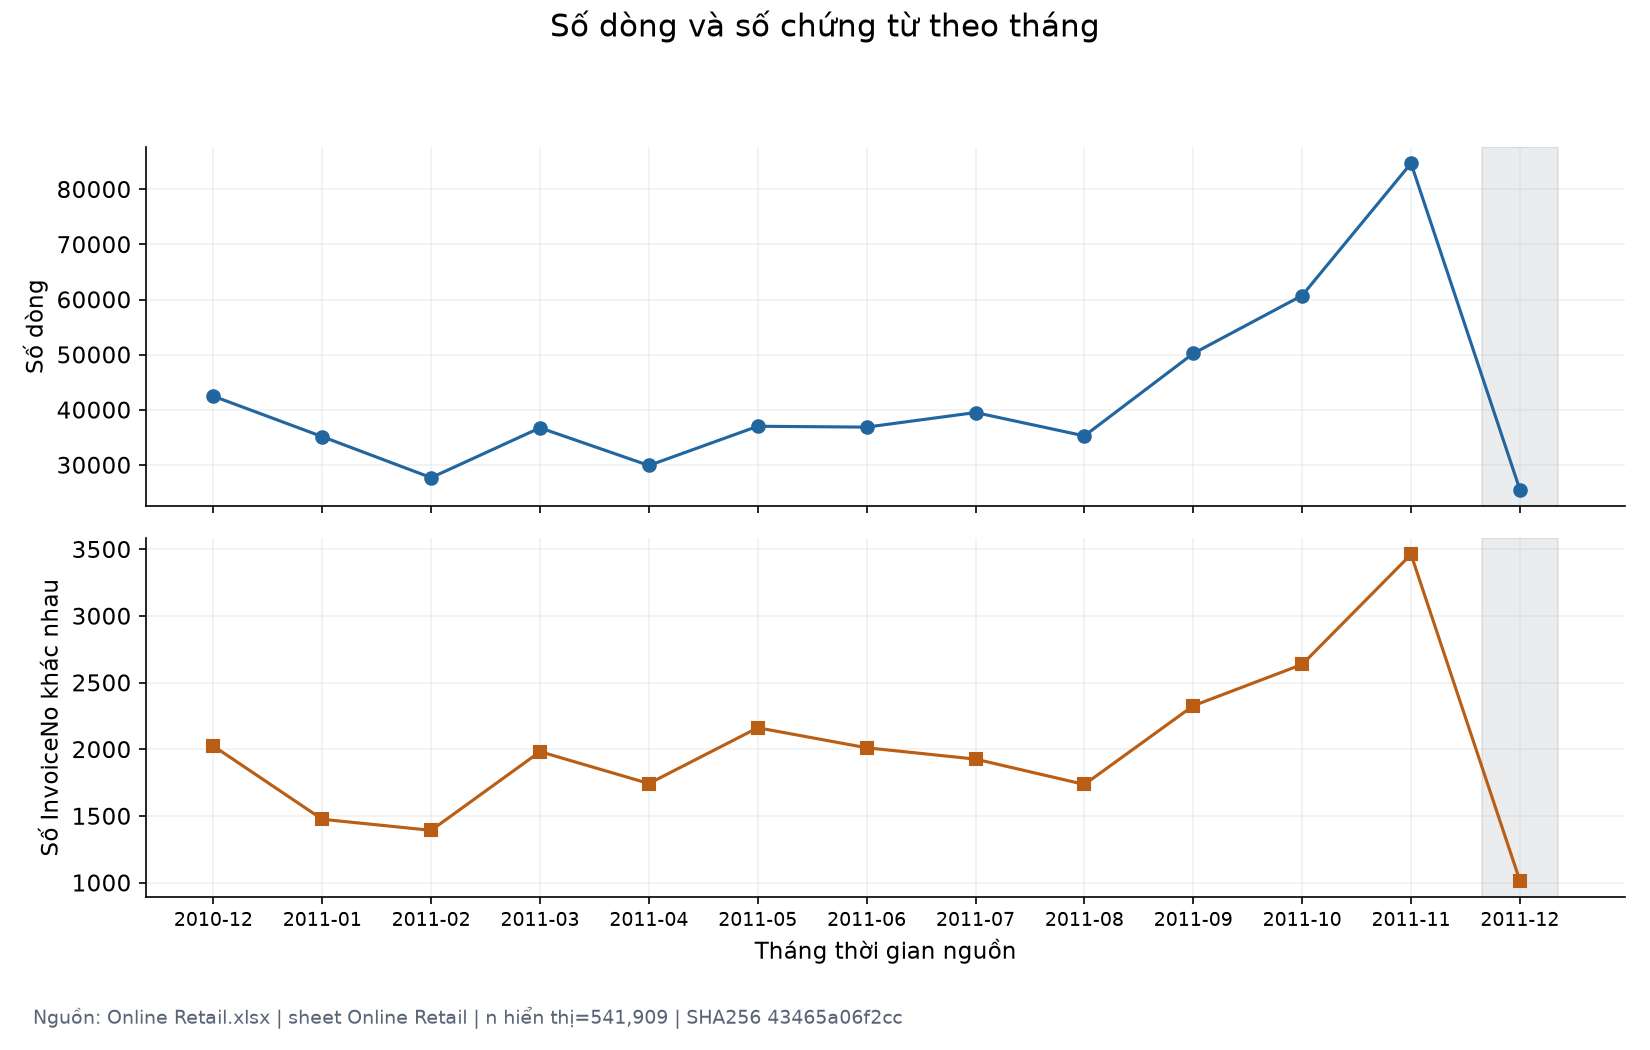

**Phạm vi:** Toàn bộ raw

**Quan sát:** Tháng có nhiều dòng nhất trong cửa sổ là 2011-11.

**Bằng chứng:** Đỉnh 84,711 dòng; tháng cuối 2011-12 có 25,525 dòng và chỉ đến 2011-12-09 12:50:00.

**Ý nghĩa:** Cửa sổ dữ liệu và mùa vụ có thể ảnh hưởng tần suất/giá trị quan sát của khách.

**Giới hạn / câu hỏi tiếp:** Tháng cuối thiếu ngày; không diễn giải giảm tháng cuối như suy giảm kinh doanh. Dữ liệu từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00, chưa rõ múi giờ; các tổng chưa xác định là doanh thu thuần.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): monthly_activity (T27), analysis_scopes (T39)

In [35]:
show_figure("monthly_activity")

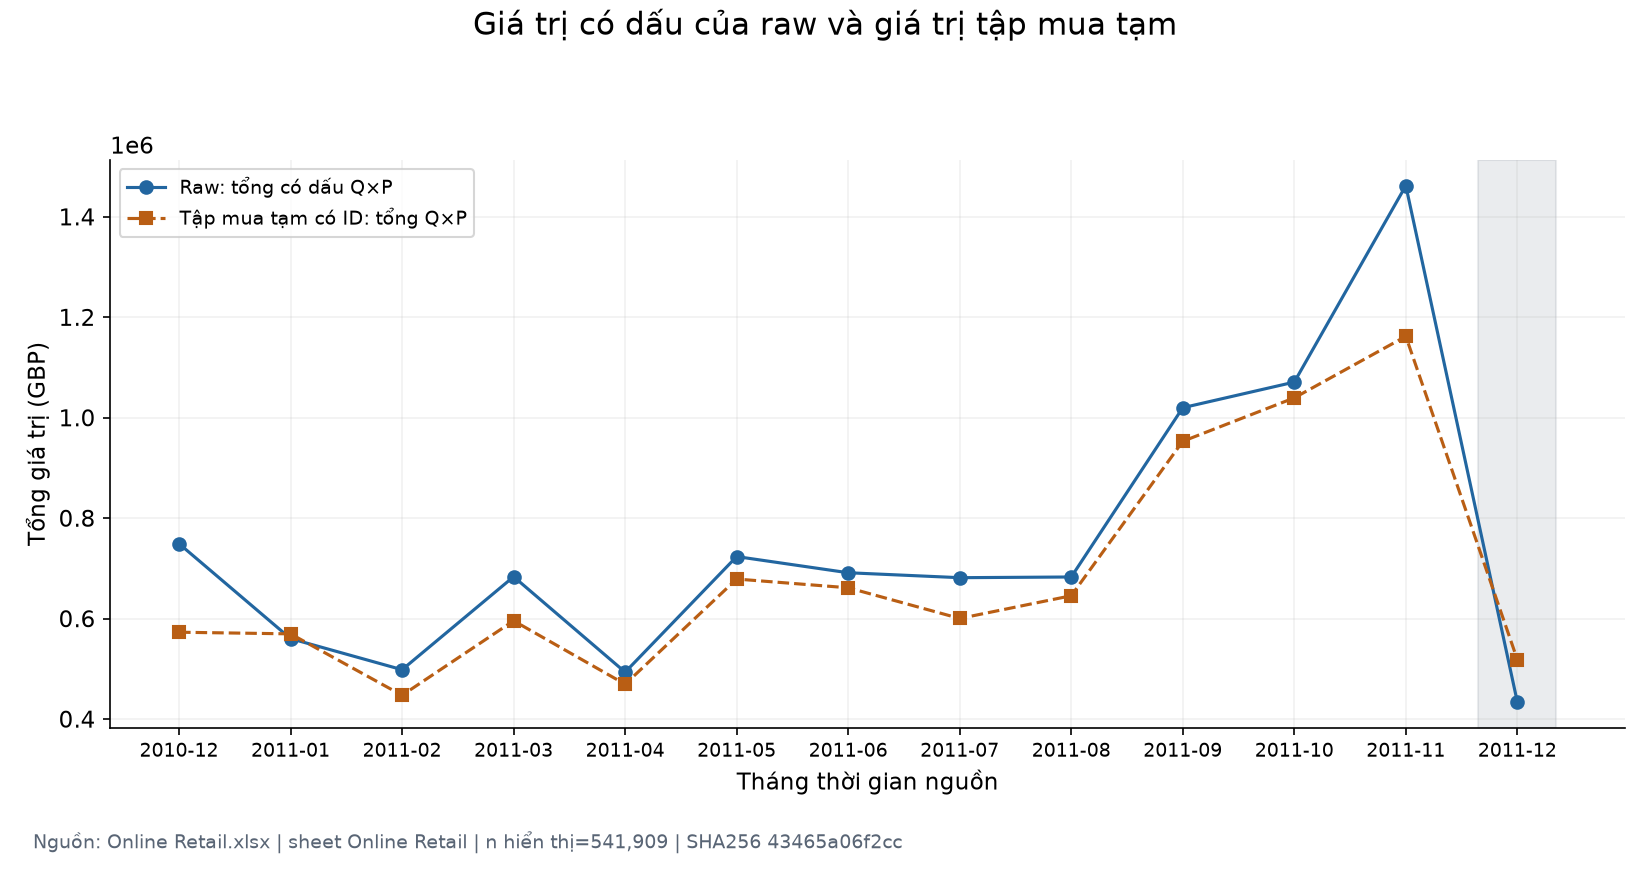

**Phạm vi:** Toàn bộ raw

**Quan sát:** Hai tổng thuộc hai phạm vi; chênh lệch phản ánh cả điều kiện lọc và dòng vô danh.

**Bằng chứng:** Raw có dấu 9,747,747.93 GBP; tập mua tạm 8,911,407.90 GBP.

**Ý nghĩa:** Cửa sổ dữ liệu và mùa vụ có thể ảnh hưởng tần suất/giá trị quan sát của khách.

**Giới hạn / câu hỏi tiếp:** Tháng cuối thiếu ngày; không diễn giải giảm tháng cuối như suy giảm kinh doanh. Dữ liệu từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00, chưa rõ múi giờ; các tổng chưa xác định là doanh thu thuần.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): monthly_activity (T27), analysis_scopes (T39)

In [36]:
show_figure("monthly_values")

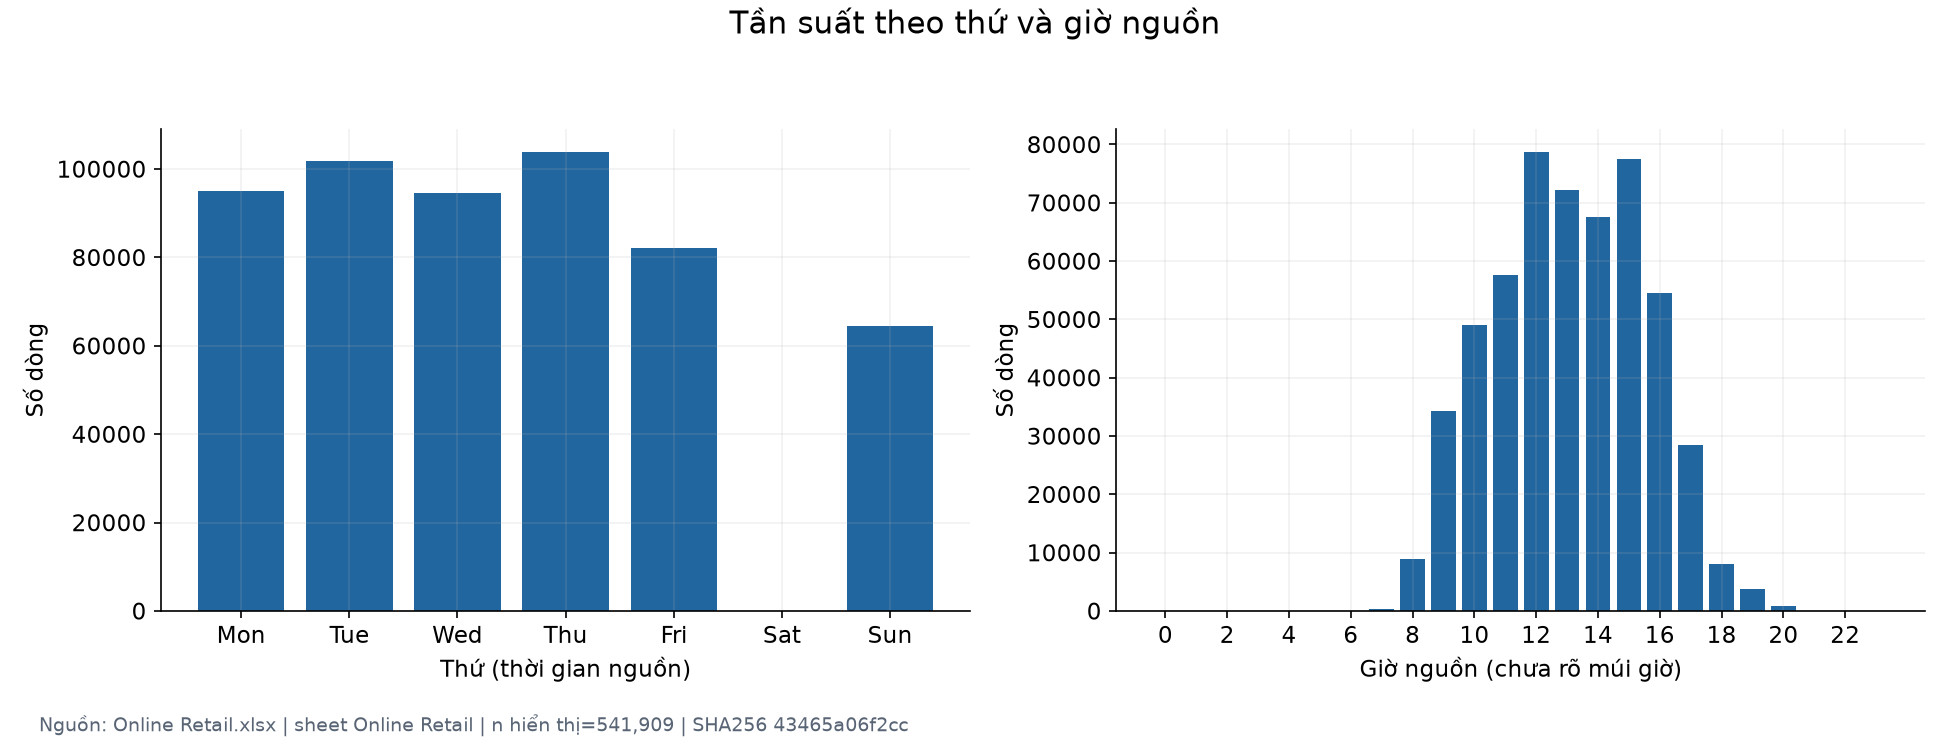

**Phạm vi:** Toàn bộ raw

**Quan sát:** Nhiều dòng nhất tại giờ 12.

**Bằng chứng:** Giờ 12: 78,709 dòng; thứ Bảy: 0 dòng.

**Ý nghĩa:** Có thể đề xuất đặc trưng tỷ lệ giao dịch theo thời điểm sau khi hiểu quy trình ghi nhận.

**Giới hạn / câu hỏi tiếp:** Tần suất gộp phụ thuộc số ngày được ghi nhận và lượng dòng mỗi đơn; không chứng minh giờ đặt hàng thực hay lịch mở cửa.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): weekday_counts (T28), hour_counts (T29)

In [37]:
show_figure("weekday_hour")

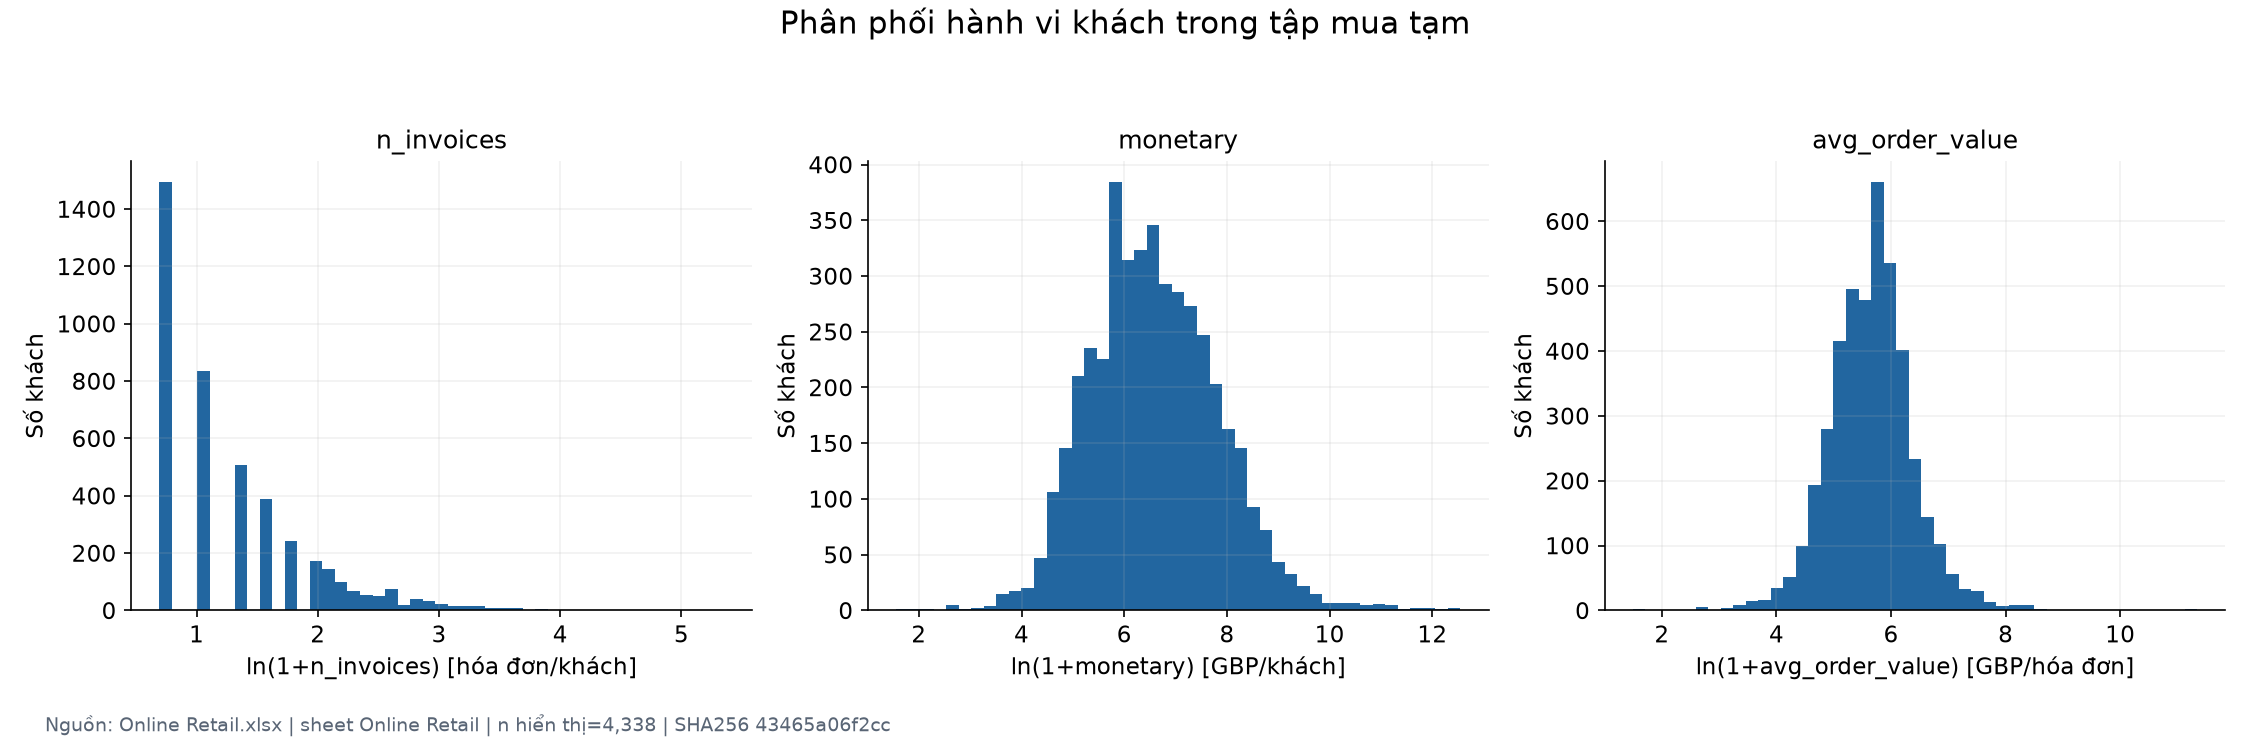

**Phạm vi:** InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean.

**Quan sát:** Tần suất và giá trị quan sát khác nhau giữa khách.

**Bằng chứng:** n_invoices: median 2.00, p99 30.00, max 209.00; monetary: median 674.49, p99 19,881.00, max 280,206.02; avg_order_value: median 293.90, p99 2,031.16, max 84,236.25

**Ý nghĩa:** Phân vị hỗ trợ so sánh RobustScaler/log1p với các cách giữ nguyên thang ở bước sau.

**Giới hạn / câu hỏi tiếp:** Chỉ biến đổi tọa độ hiển thị; chưa fit scaler. Giữ trùng và mã dịch vụ có thể ảnh hưởng tổng; không phải bộ đặc trưng chính thức.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): customer_summary (T21), customer_coverage (T40), aggregation_formulas (T38)

In [38]:
show_figure("customer_distributions")

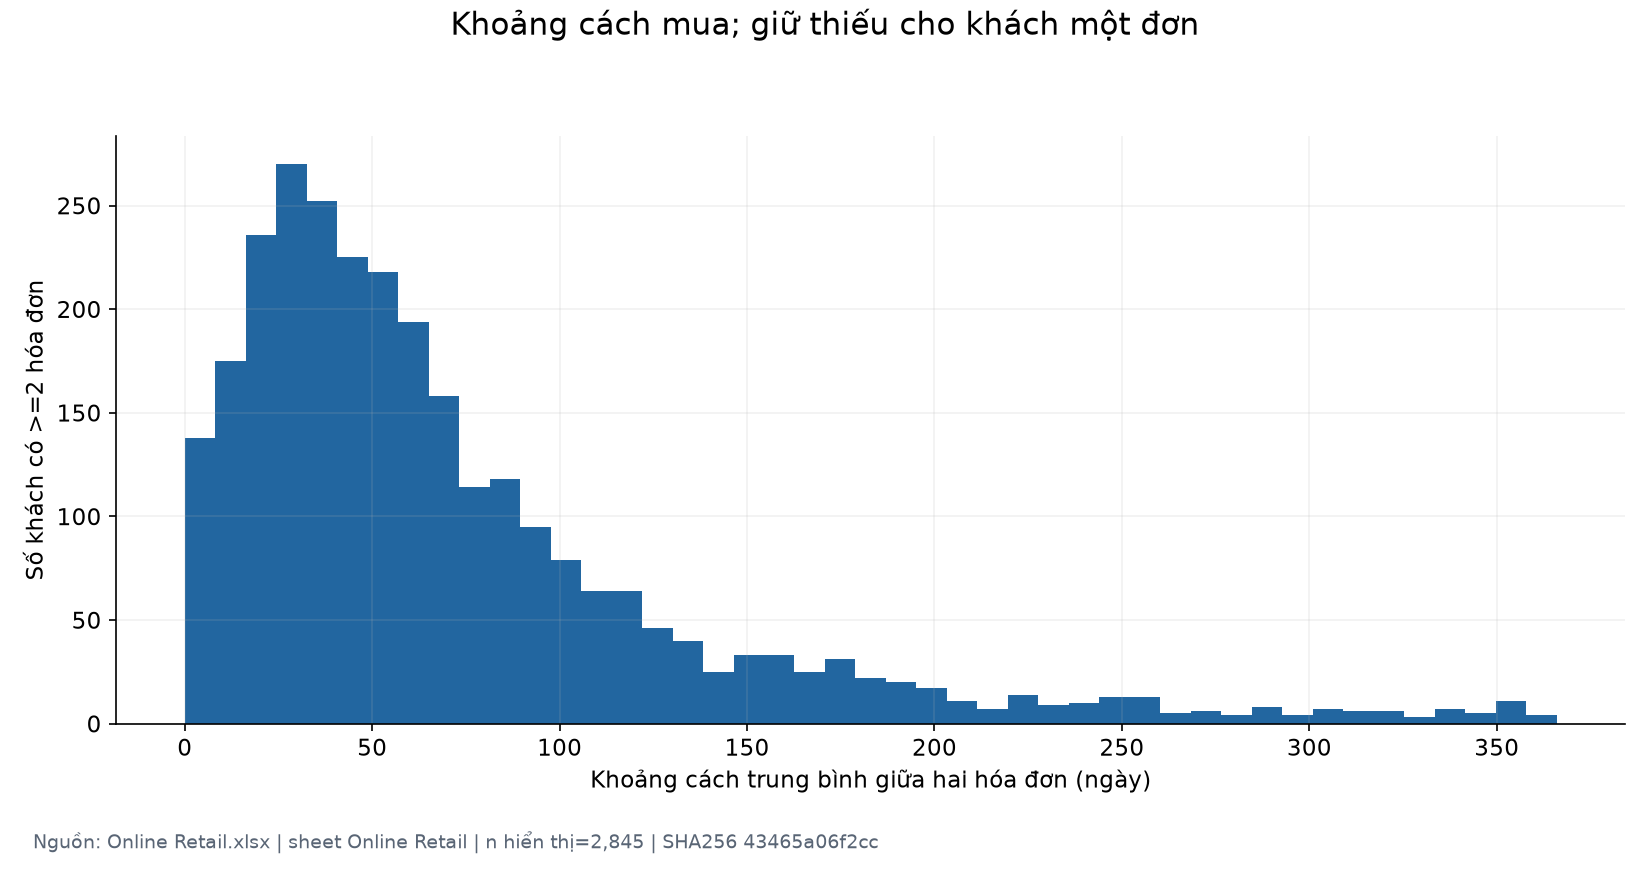

**Phạm vi:** Khách có >=2 hóa đơn trong tập mua tạm; min timestamp mỗi hóa đơn

**Quan sát:** Khoảng cách chỉ xác định khi quan sát ít nhất hai hóa đơn.

**Bằng chứng:** 1,493/4,338 khách có một hóa đơn (34.42%), giữ NaN; 2,845 khách có gap, median 53.46 ngày.

**Ý nghĩa:** Thiếu gap là thiếu do cấu trúc hành vi, không phải mặc định khoảng cách bằng 0.

**Giới hạn / câu hỏi tiếp:** Hóa đơn khác nhau có thể cùng thời điểm (gap 0 hợp lệ); chưa xác nhận hóa đơn trùng nghiệp vụ và không quan sát trước/sau cửa sổ raw.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): customer_summary (T21), customer_coverage (T40), aggregation_formulas (T38)

In [39]:
show_figure("customer_gaps")

## 6. Hai biến và đa biến

Chọn Quantity–UnitPrice để xem hành vi lượng/giá; số hóa đơn–giá trị để xem cường độ mua;
giá trị dòng–quốc gia để so phân phối với cỡ mẫu; quốc gia–trạng thái chứng từ để xem thành phần.
Hai scatter đa biến kiểm tra tần suất/giá trị đơn và đa dạng mã/giá trị, màu là recency.
Scatter đa biến lấy mẫu có seed; các thống kê và tương quan luôn dùng toàn bộ tập đủ điều kiện.

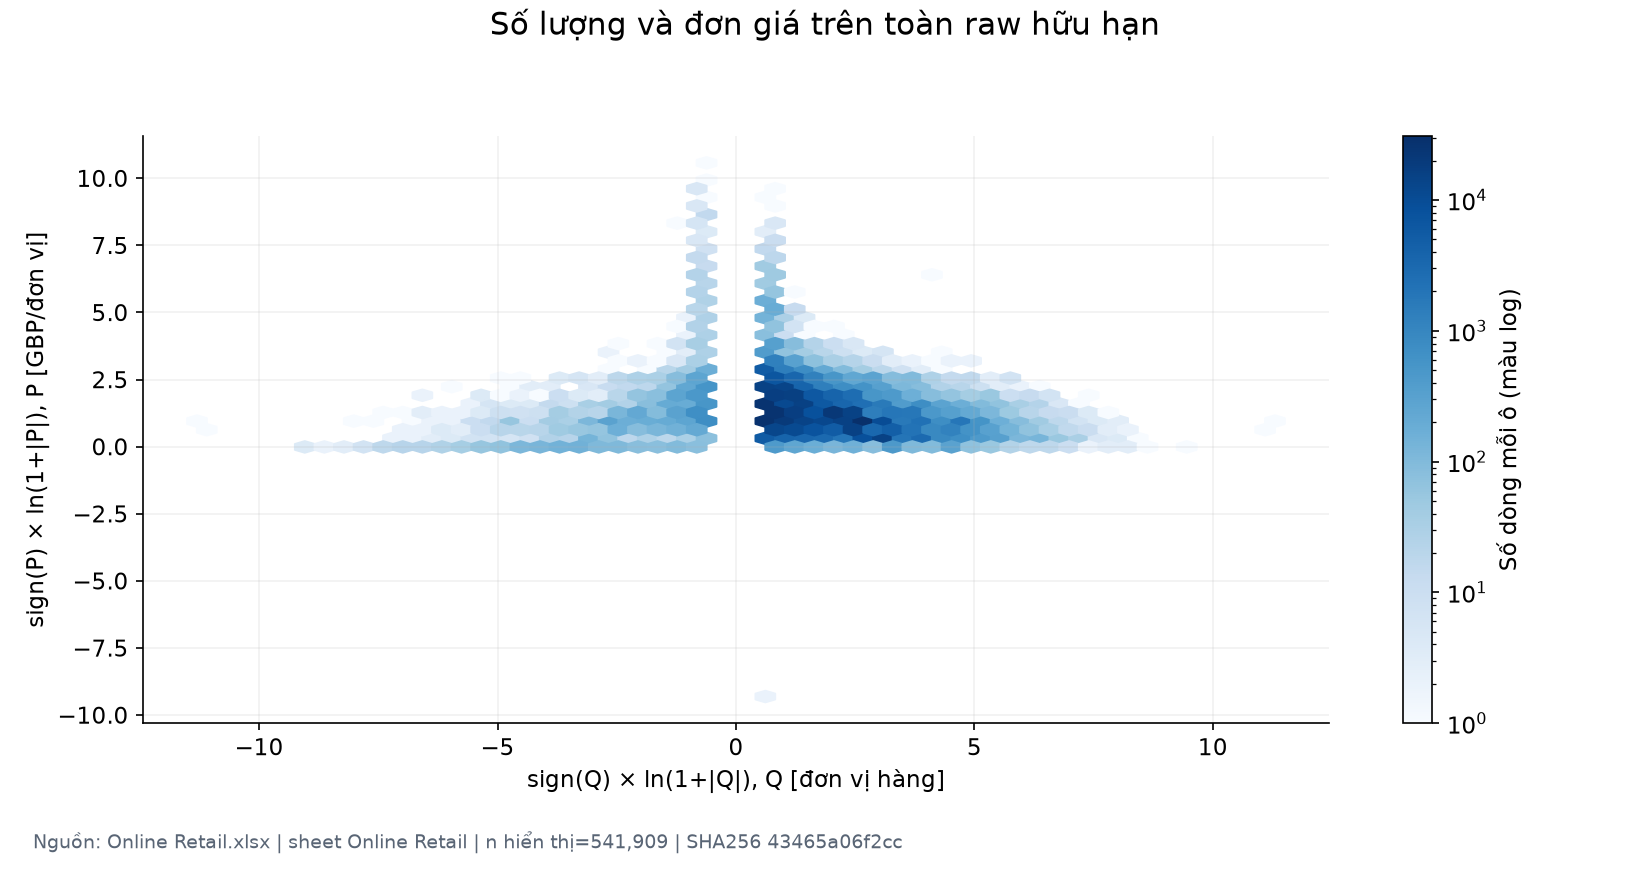

**Phạm vi:** Toàn bộ raw

**Quan sát:** Mật độ tập trung theo miền giá/số lượng; hai hệ số có thể khác nhau do đuôi và thứ hạng.

**Bằng chứng:** Quantity–UnitPrice: n=541,909, Pearson=-0.0012, Spearman=-0.3854.

**Ý nghĩa:** Kiểm tra dạng quan hệ trước khi cân nhắc đặc trưng số lượng/giá.

**Giới hạn / câu hỏi tiếp:** Hexbin dùng toàn bộ cặp hữu hạn, không lấy mẫu; đổi tọa độ chỉ để nhìn. Không diễn giải tương quan là nhân quả hay cầu theo giá.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_line_pearson (T32), correlations_line_spearman (T33), correlations_line_pairwise_counts (T34), numeric_summary (T20)

In [40]:
show_figure("quantity_price_hexbin")

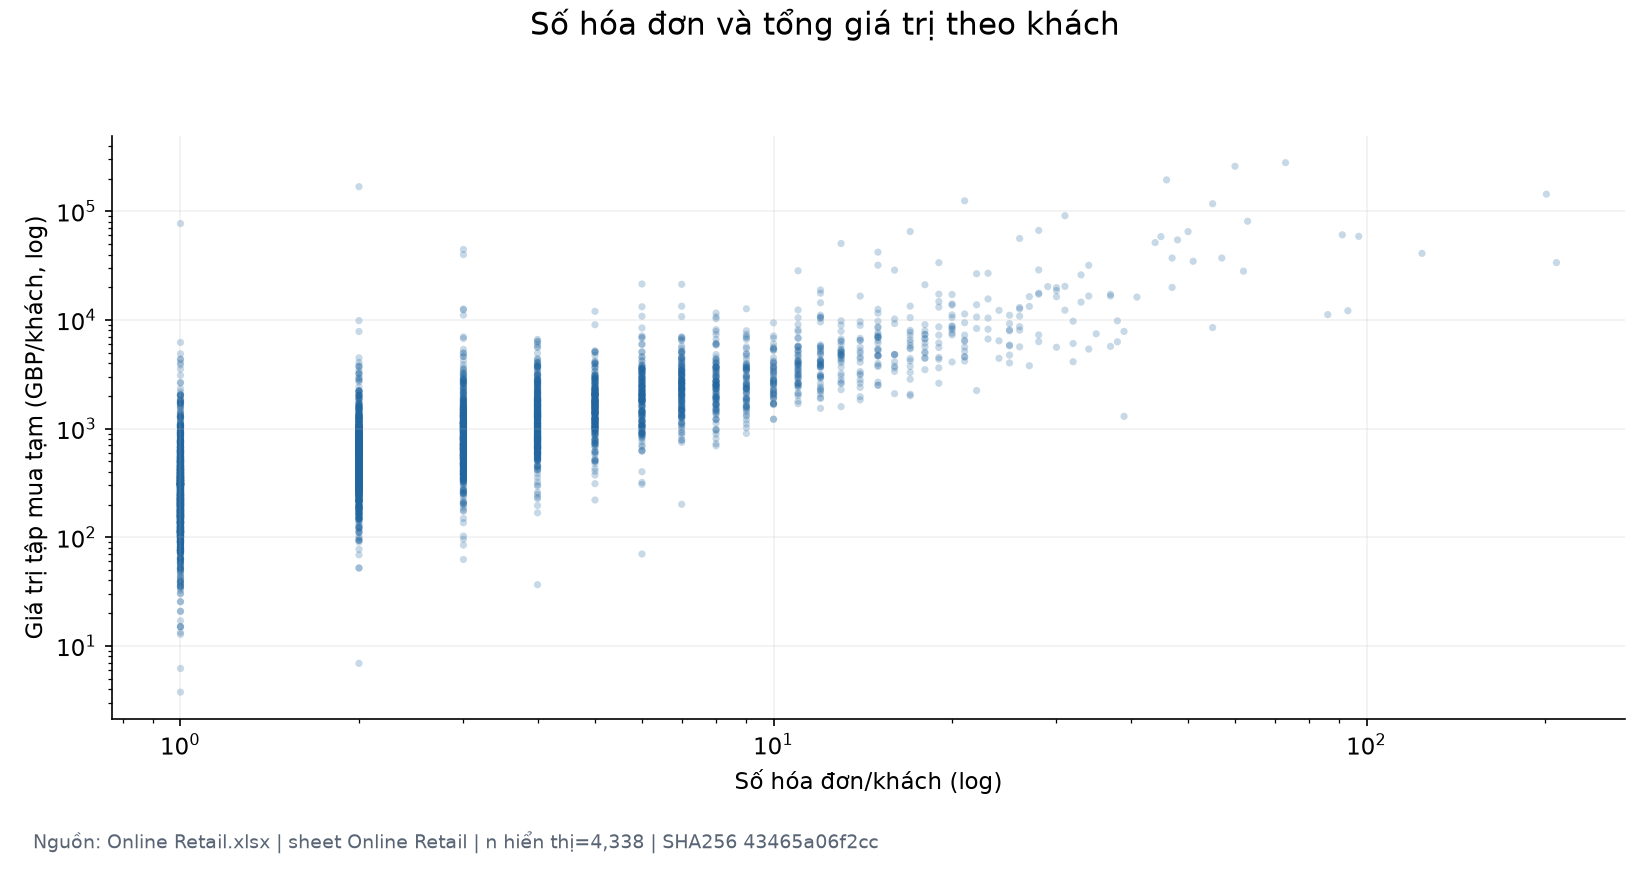

**Phạm vi:** InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean.

**Quan sát:** Các điểm trải rộng về giá trị ngay tại cùng số hóa đơn.

**Bằng chứng:** n_invoices–monetary: n=4,338, Pearson=0.5536, Spearman=0.8075.

**Ý nghĩa:** Cần đánh giá tần suất cùng giá trị đơn, thay vì chọn một hệ số duy nhất.

**Giới hạn / câu hỏi tiếp:** Toàn bộ khách, không mẫu/cắt; tổng giá trị phụ thuộc số đơn và giá trị đơn; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_customer_pearson (T35), correlations_customer_spearman (T36), correlations_customer_pairwise_counts (T37)

In [41]:
show_figure("customer_frequency_value")

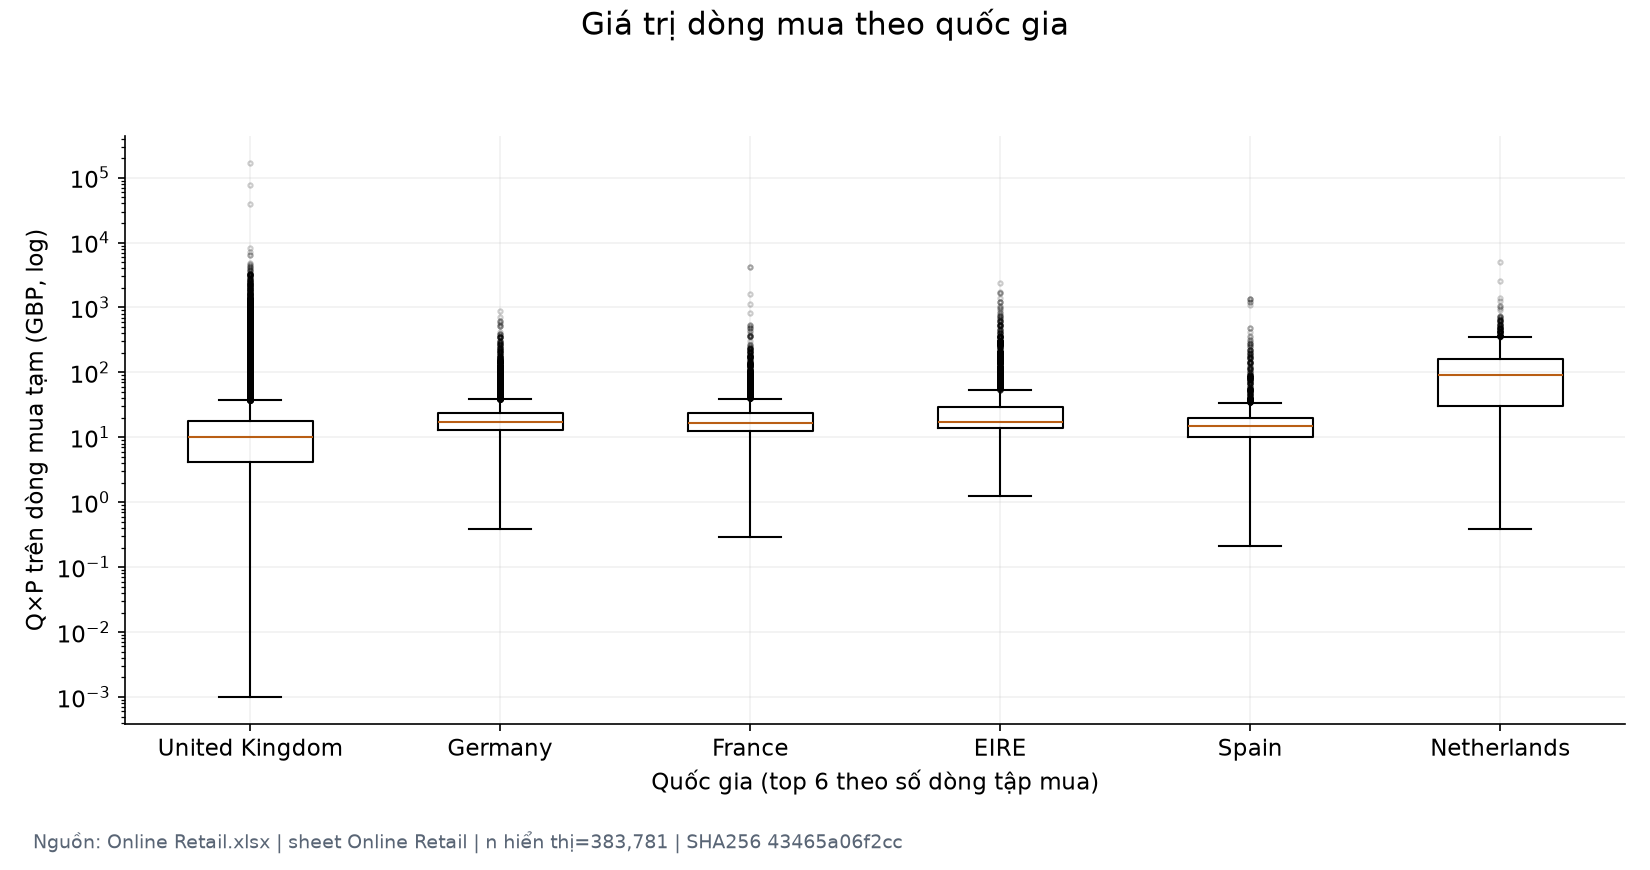

**Phạm vi:** InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean. Top 6 quốc gia theo số dòng; không cắt cực trị.

**Quan sát:** Phân phối giá trị trên dòng cần đọc cùng cỡ mẫu khác nhau của quốc gia.

**Bằng chứng:** United Kingdom: n=354,321, median=10.20 GBP; Germany: n=9,040, median=17.00 GBP; France: n=8,341, median=16.60 GBP; EIRE: n=7,236, median=17.40 GBP; Spain: n=2,484, median=15.00 GBP; Netherlands: n=2,359, median=91.80 GBP

**Ý nghĩa:** Đánh giá đặc trưng quốc gia cùng hành vi, tránh để nhóm có nhiều dòng chi phối kết luận.

**Giới hạn / câu hỏi tiếp:** Không phải giá trị mỗi khách; 14,103 dòng ngoài top 6 không hiện. Không kiểm định khác biệt hay khẳng định quốc gia gây ra giá trị mua.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): country_value_summary (T31), analysis_scopes (T39)

In [42]:
show_figure("country_value_boxplot")

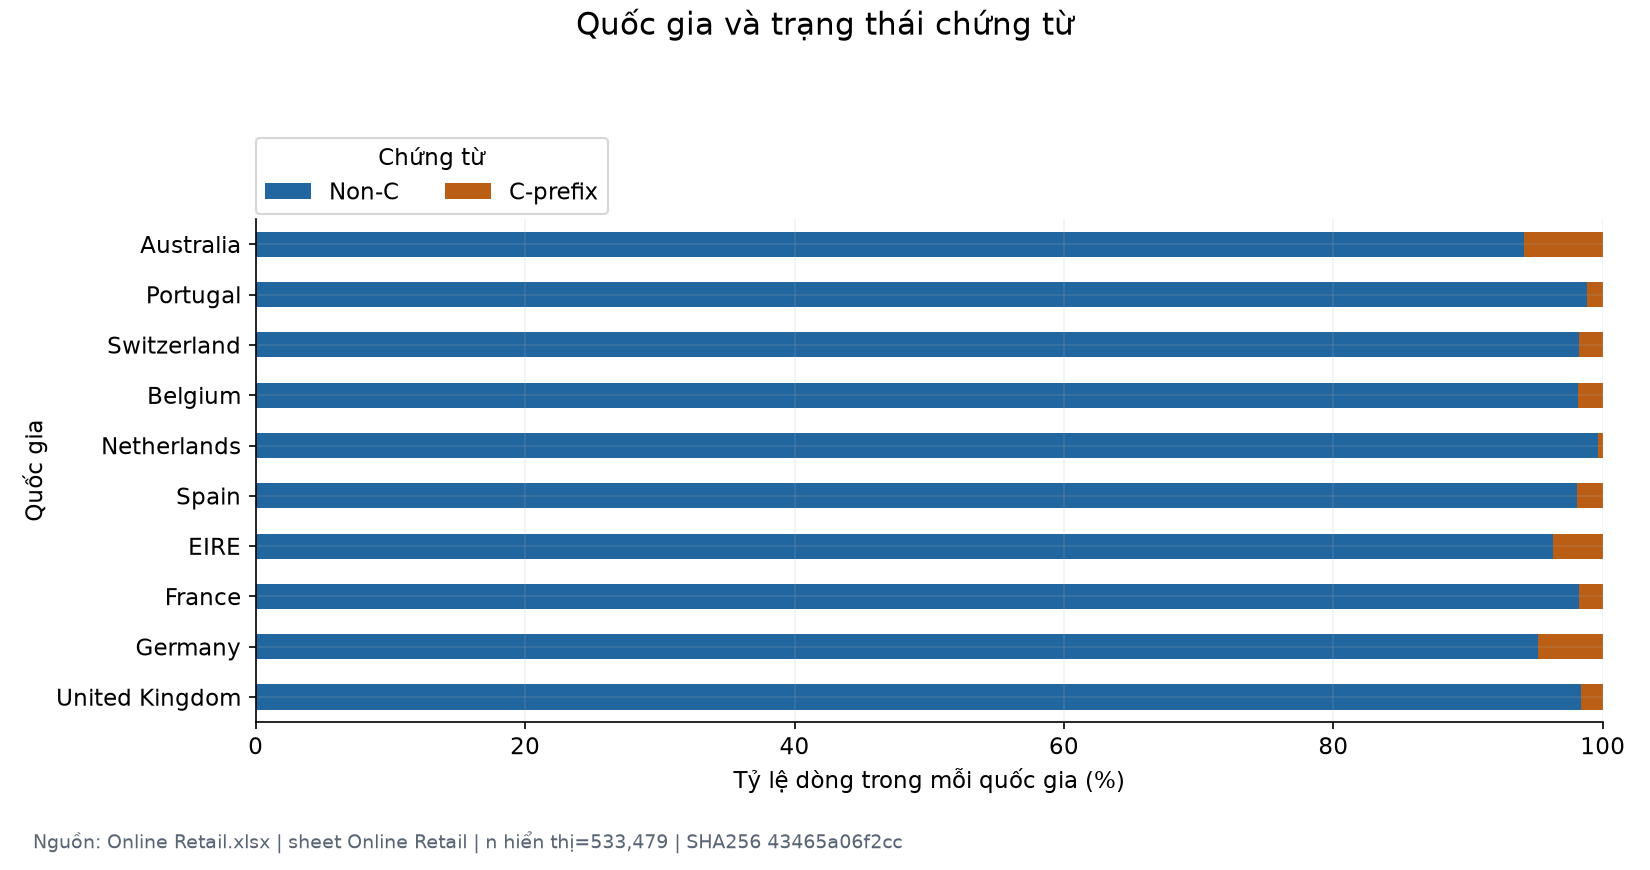

**Phạm vi:** Raw, top 10 quốc gia theo số dòng; tỷ lệ theo tổng dòng mỗi quốc gia

**Quan sát:** Thành phần chứng từ C được so sánh theo mẫu số riêng từng quốc gia.

**Bằng chứng:** United Kingdom: C 7,856/495,478 dòng (1.59%); Germany: C 453/9,495 dòng (4.77%); France: C 149/8,557 dòng (1.74%); EIRE: C 302/8,196 dòng (3.68%)

**Ý nghĩa:** Cần làm rõ cách nhận diện trả hàng trước khi thêm tỷ lệ hoàn trả theo khách/nhóm.

**Giới hạn / câu hỏi tiếp:** 8,430 dòng ngoài top 10 không hiện; tỷ lệ chứng từ C không phải tỷ lệ hàng trả và không ghép đơn mua gốc.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): country_document_counts (T30), country_counts (T23)

In [43]:
show_figure("country_document_status")

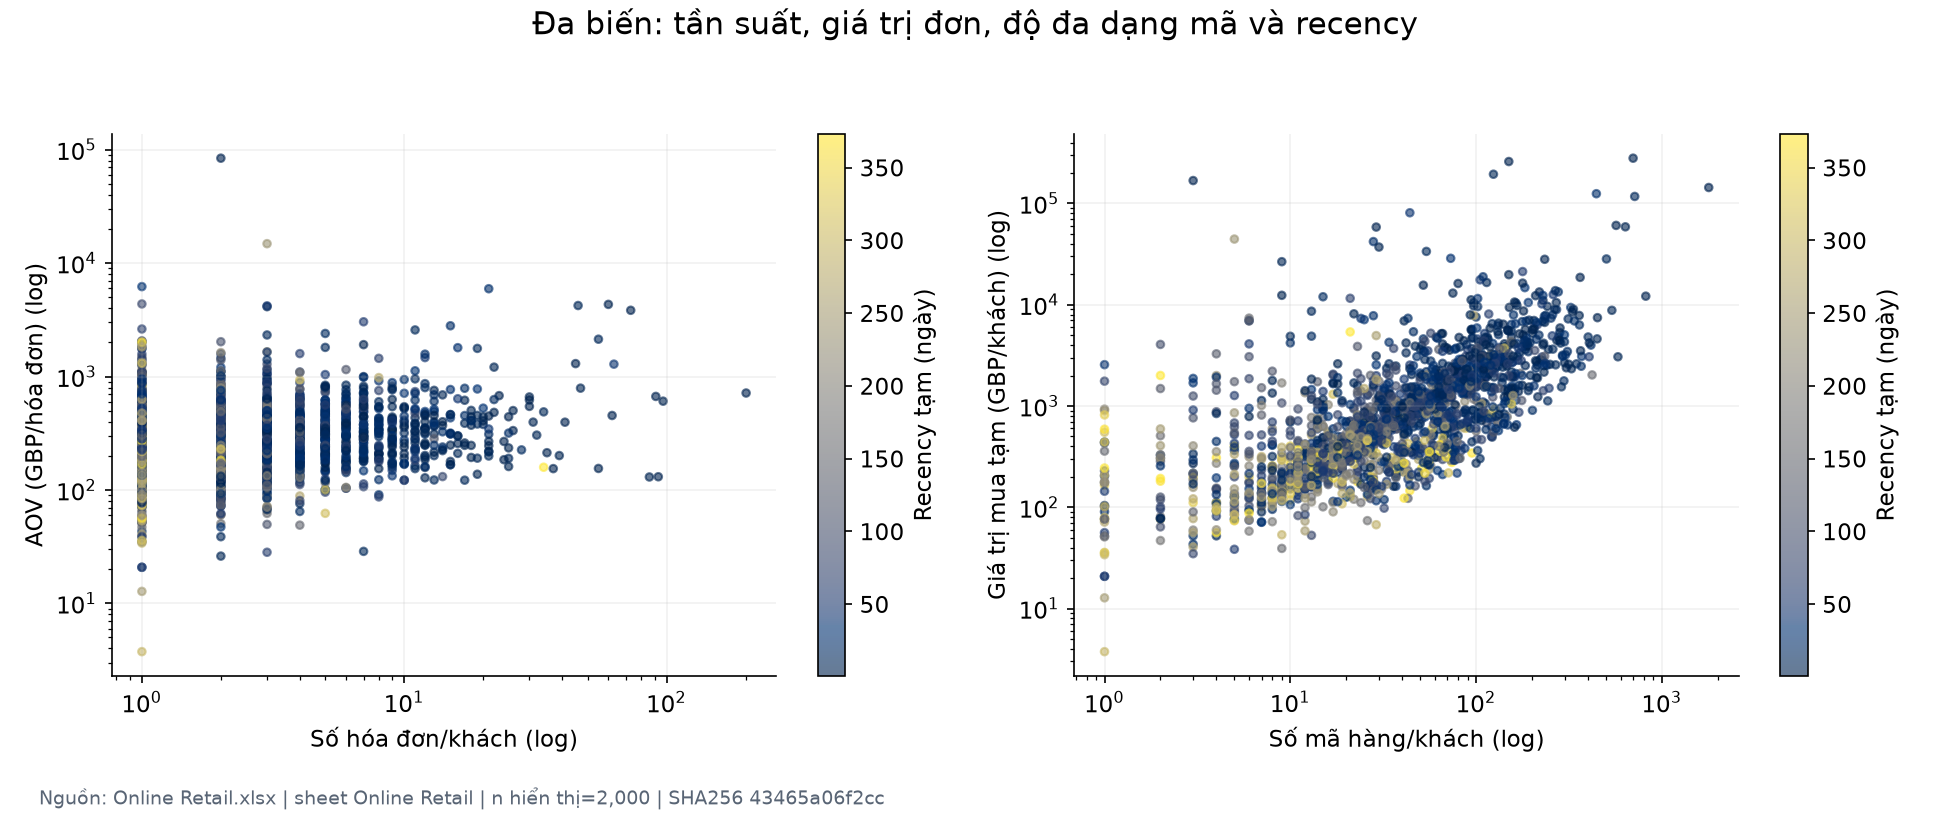

**Phạm vi:** Mẫu 2,000/4,338 khách của tập mua tạm, random_state=1505

**Quan sát:** Các cặp kiểm tra sự bổ sung giữa cường độ mua, giá trị mỗi đơn và số mã mua.

**Bằng chứng:** n_invoices–avg_order_value: n=4,338, Pearson=0.0191, Spearman=0.1553. n_stock_codes–monetary: n=4,338, Pearson=0.3870, Spearman=0.7264.

**Ý nghĩa:** Cân nhắc thông tin trùng lặp giữa RFM và biến hành vi trước khi chọn tập biến.

**Giới hạn / câu hỏi tiếp:** Hệ số tính trên toàn bộ khách đủ điều kiện theo cặp; scatter chỉ mẫu. Màu recency là mô tả, không là nhãn hay dự báo; mã hàng chưa phân loại sản phẩm.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_customer_pearson (T35), correlations_customer_spearman (T36), customer_summary (T21), aggregation_formulas (T38)

In [44]:
show_figure("customer_multivariate")

## 7. Tương quan

**Pearson** đo liên hệ tuyến tính; **Spearman** đo liên hệ đơn điệu theo hạng.
Hai cấp phân tích tách riêng: toàn bộ dòng raw và tổng hợp khách trong tập mua tạm.
Ma trận tính trên toàn bộ giá trị hữu hạn theo cặp (`min_periods=3`), không lấy mẫu/điền 0.
Mỗi cấp có cùng tập biến cho hai hệ số và bảng số cặp hợp lệ.

IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc đại số;
tương quan cao không tự đòi hỏi loại biến, cũng không chứng minh quan hệ nhân quả.
Scatter ở phần 6 giúp đọc hình dạng quan hệ thay vì chỉ nhìn hệ số.

In [45]:
show_table("correlation_variable_audit", limit=20)

**correlation_variable_audit** — 15 dòng × 3 cột; sheet T41 trong workbook kết quả.

,variable,decision,note
0,InvoiceNo,excluded identifier,Không có ý nghĩa như số liên tục
1,CustomerID,excluded identifier,Không có ý nghĩa như số liên tục
2,StockCode,excluded identifier,Không có ý nghĩa như số liên tục
3,Quantity,included numeric,Đo trực tiếp
4,UnitPrice,included numeric,Đo trực tiếp
5,SignedLineValue,included numeric,Q*P
6,n_invoices,included numeric,Tổng hợp tạm
7,monetary,included numeric,Tổng hợp tạm
8,avg_order_value,included numeric,M/F; phụ thuộc đại số
9,n_stock_codes,included numeric,Tổng hợp tạm


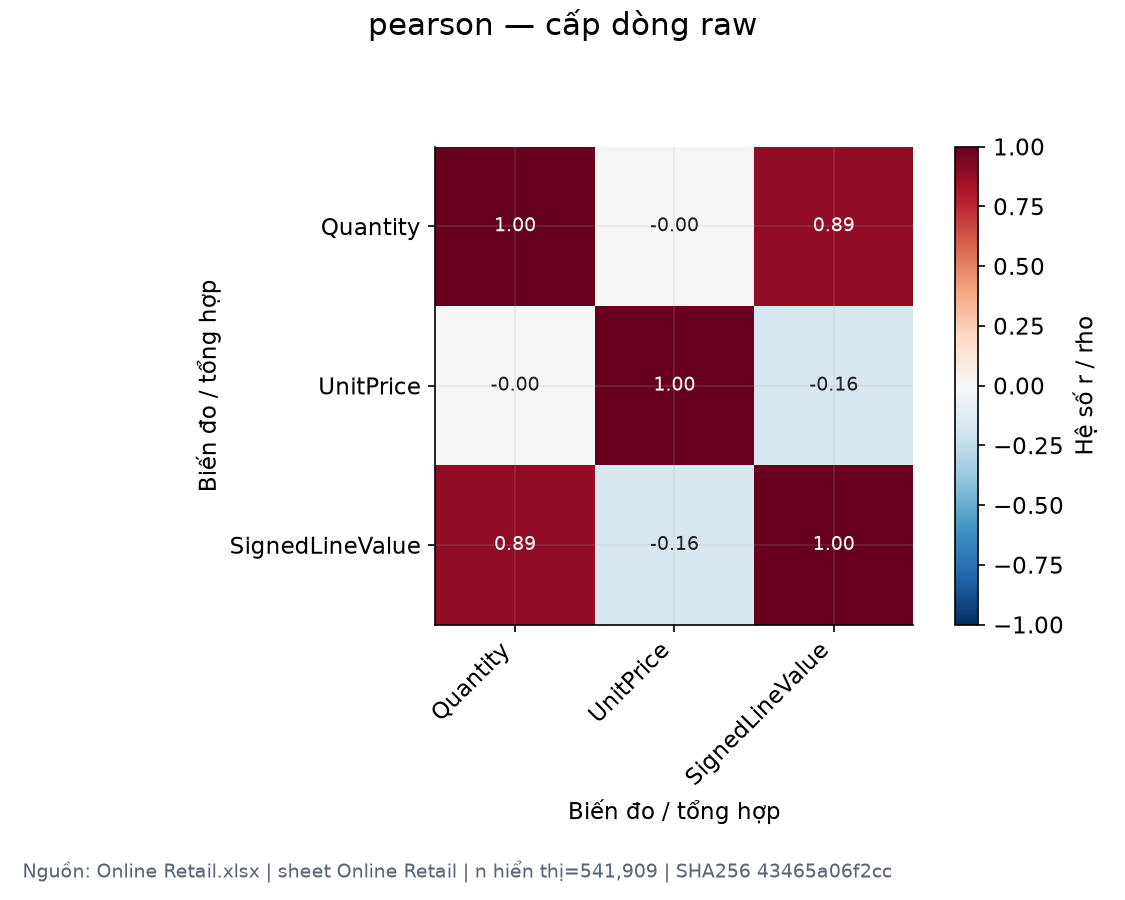

**Phạm vi:** Toàn bộ dòng raw hữu hạn theo cặp

**Quan sát:** Pearson mô tả tuyến tính; Spearman mô tả đơn điệu theo hạng, nhạy khác nhau với cực trị.

**Bằng chứng:** Quantity–UnitPrice: n=541,909, Pearson=-0.0012, Spearman=-0.3854.

**Ý nghĩa:** Chọn biến theo ý nghĩa và độ trùng thông tin, không tự loại chỉ vì hệ số cao.

**Giới hạn / câu hỏi tiếp:** Pairwise finite deletion, min_periods=3; không impute và không lấy mẫu ma trận. IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc công thức; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_line_pearson (T32), correlation_variable_audit (T41), aggregation_formulas (T38)

In [46]:
show_figure("correlation_line_pearson")

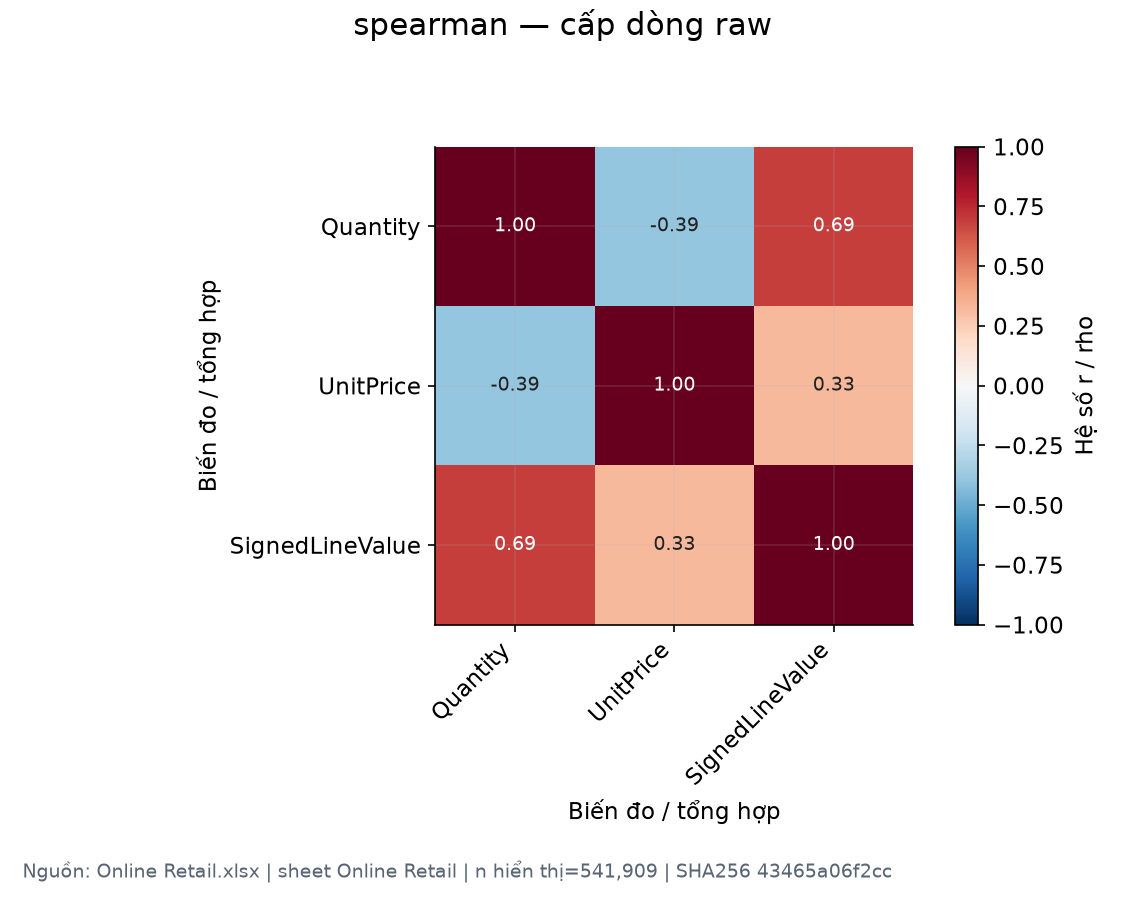

**Phạm vi:** Toàn bộ dòng raw hữu hạn theo cặp

**Quan sát:** Pearson mô tả tuyến tính; Spearman mô tả đơn điệu theo hạng, nhạy khác nhau với cực trị.

**Bằng chứng:** Quantity–UnitPrice: n=541,909, Pearson=-0.0012, Spearman=-0.3854.

**Ý nghĩa:** Chọn biến theo ý nghĩa và độ trùng thông tin, không tự loại chỉ vì hệ số cao.

**Giới hạn / câu hỏi tiếp:** Pairwise finite deletion, min_periods=3; không impute và không lấy mẫu ma trận. IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc công thức; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_line_spearman (T33), correlation_variable_audit (T41), aggregation_formulas (T38)

In [47]:
show_figure("correlation_line_spearman")

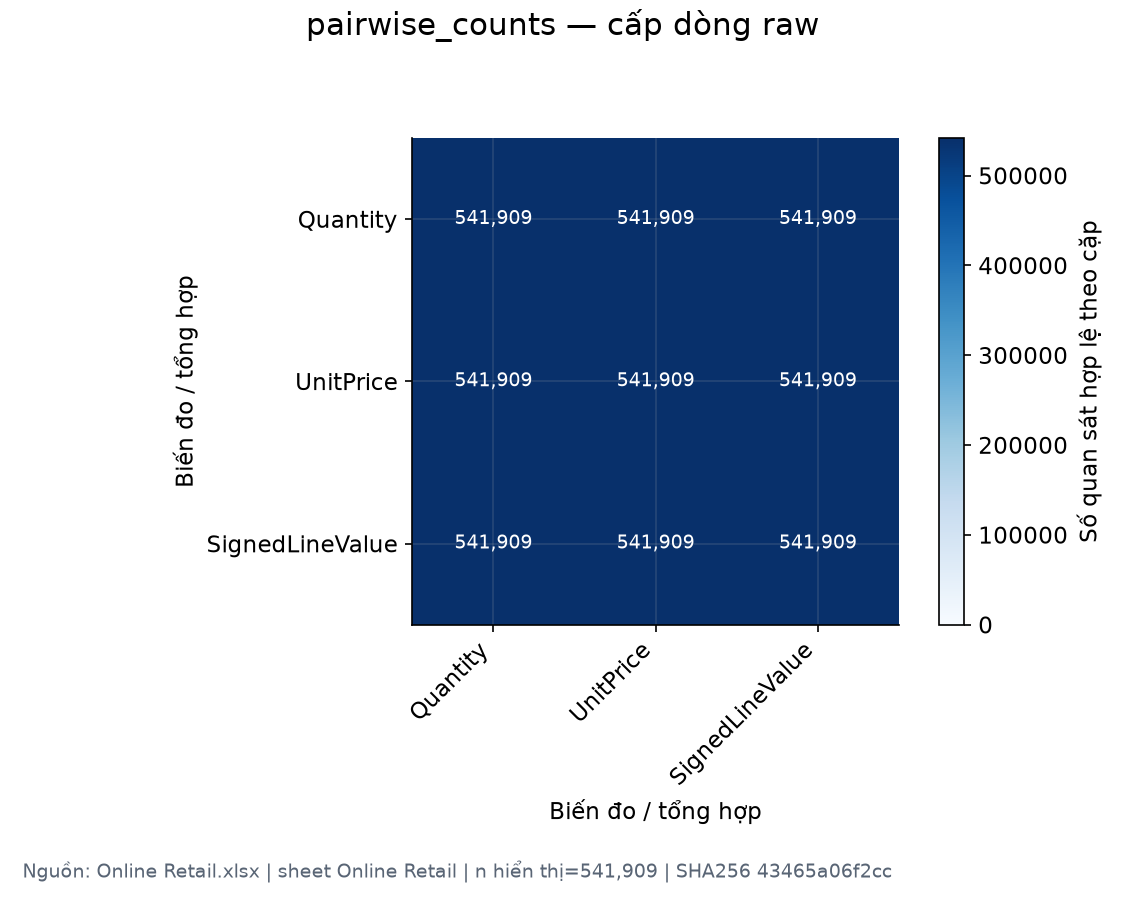

**Phạm vi:** Toàn bộ dòng raw hữu hạn theo cặp

**Quan sát:** Số cặp hợp lệ có thể khác nhau; không điền 0 cho dữ liệu chưa xác định.

**Bằng chứng:** n theo cặp từ 541,909 đến 541,909.

**Ý nghĩa:** Chọn biến theo ý nghĩa và độ trùng thông tin, không tự loại chỉ vì hệ số cao.

**Giới hạn / câu hỏi tiếp:** Pairwise finite deletion, min_periods=3; không impute và không lấy mẫu ma trận. IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc công thức; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_line_pairwise_counts (T34), correlation_variable_audit (T41), aggregation_formulas (T38)

In [48]:
show_figure("correlation_line_pairwise_counts")

In [49]:
show_table("correlations_line_pairwise_counts", limit=20)

**correlations_line_pairwise_counts** — 3 dòng × 3 cột; sheet T34 trong workbook kết quả.

,Quantity,UnitPrice,SignedLineValue
Quantity,541909,541909,541909
UnitPrice,541909,541909,541909
SignedLineValue,541909,541909,541909


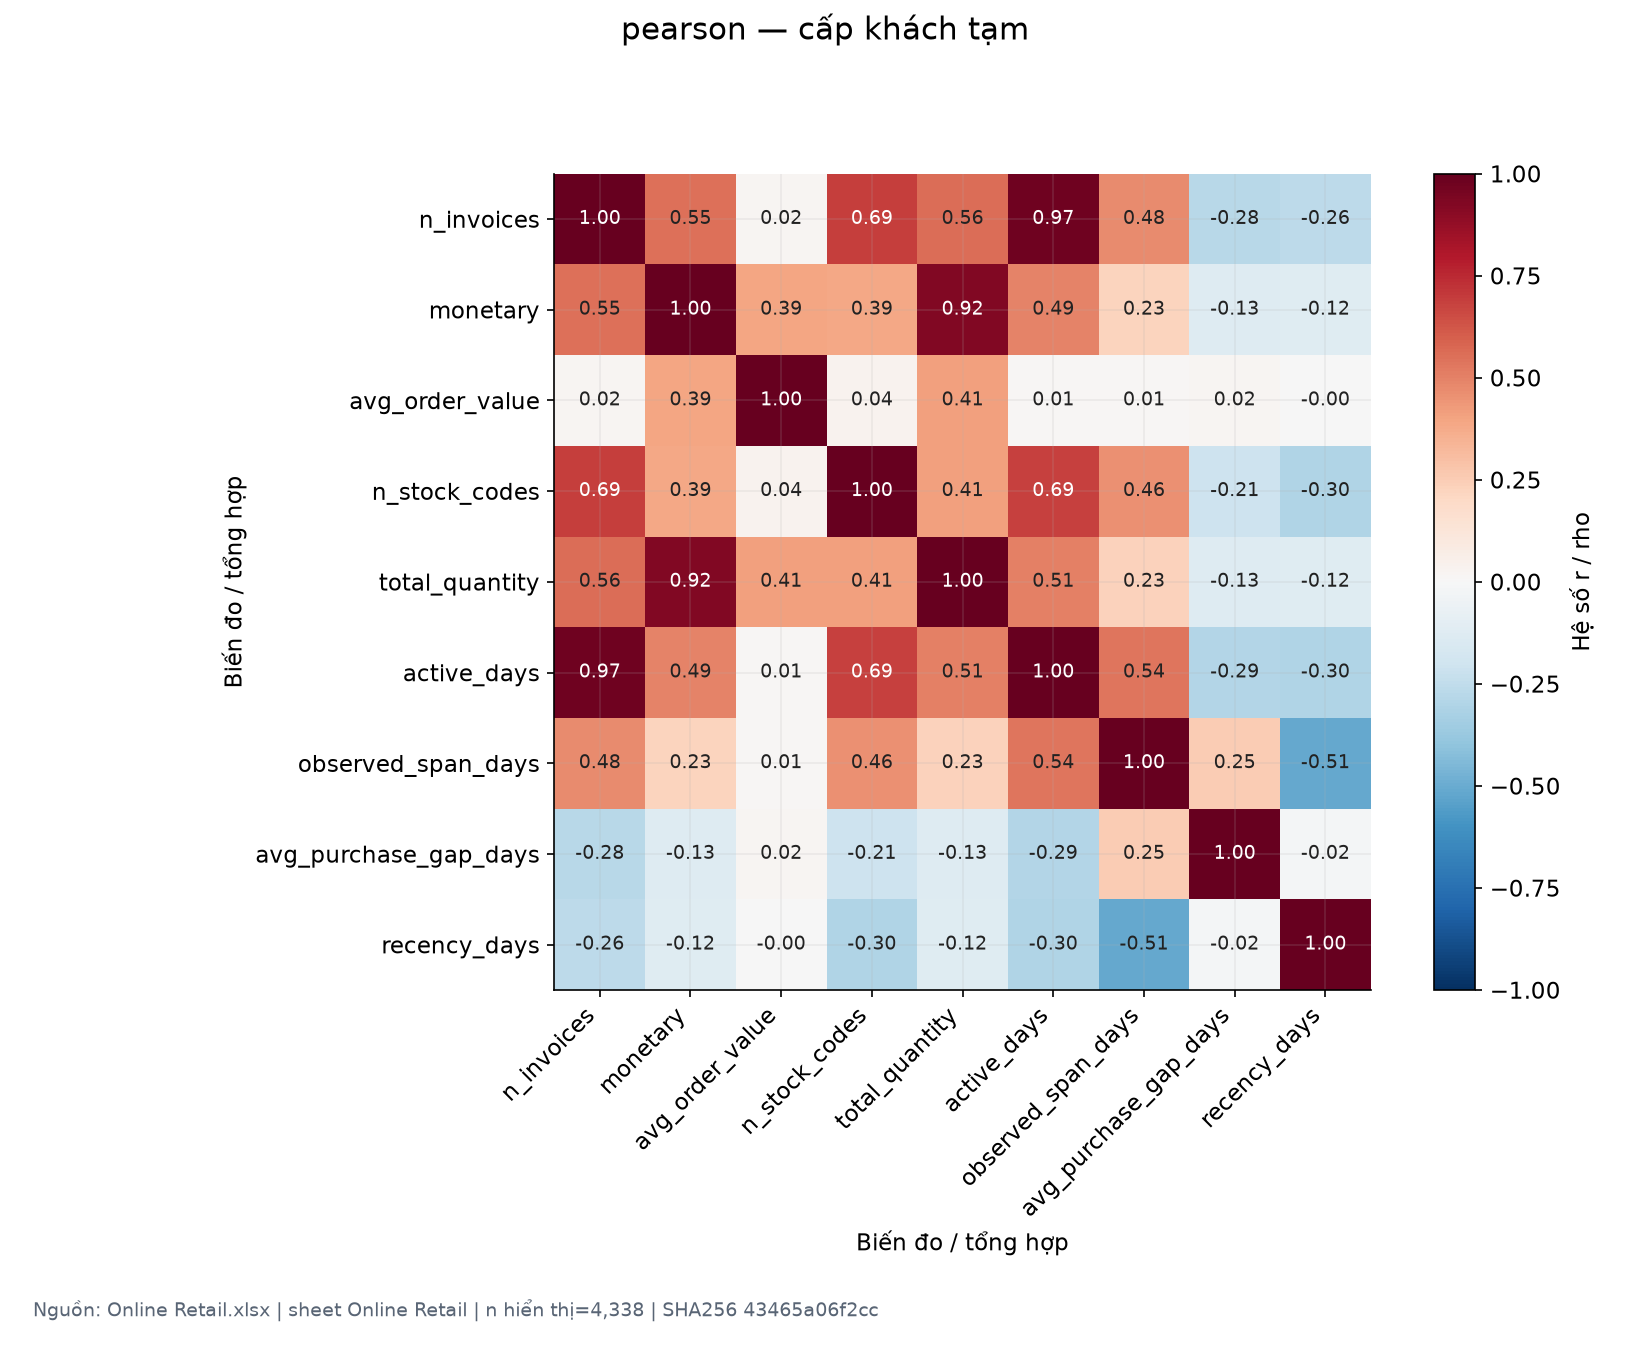

**Phạm vi:** InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean. Toàn bộ khách, hữu hạn theo cặp.

**Quan sát:** Pearson mô tả tuyến tính; Spearman mô tả đơn điệu theo hạng, nhạy khác nhau với cực trị.

**Bằng chứng:** n_invoices–monetary: n=4,338, Pearson=0.5536, Spearman=0.8075.

**Ý nghĩa:** Chọn biến theo ý nghĩa và độ trùng thông tin, không tự loại chỉ vì hệ số cao.

**Giới hạn / câu hỏi tiếp:** Pairwise finite deletion, min_periods=3; không impute và không lấy mẫu ma trận. IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc công thức; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_customer_pearson (T35), correlation_variable_audit (T41), aggregation_formulas (T38)

In [50]:
show_figure("correlation_customer_pearson")

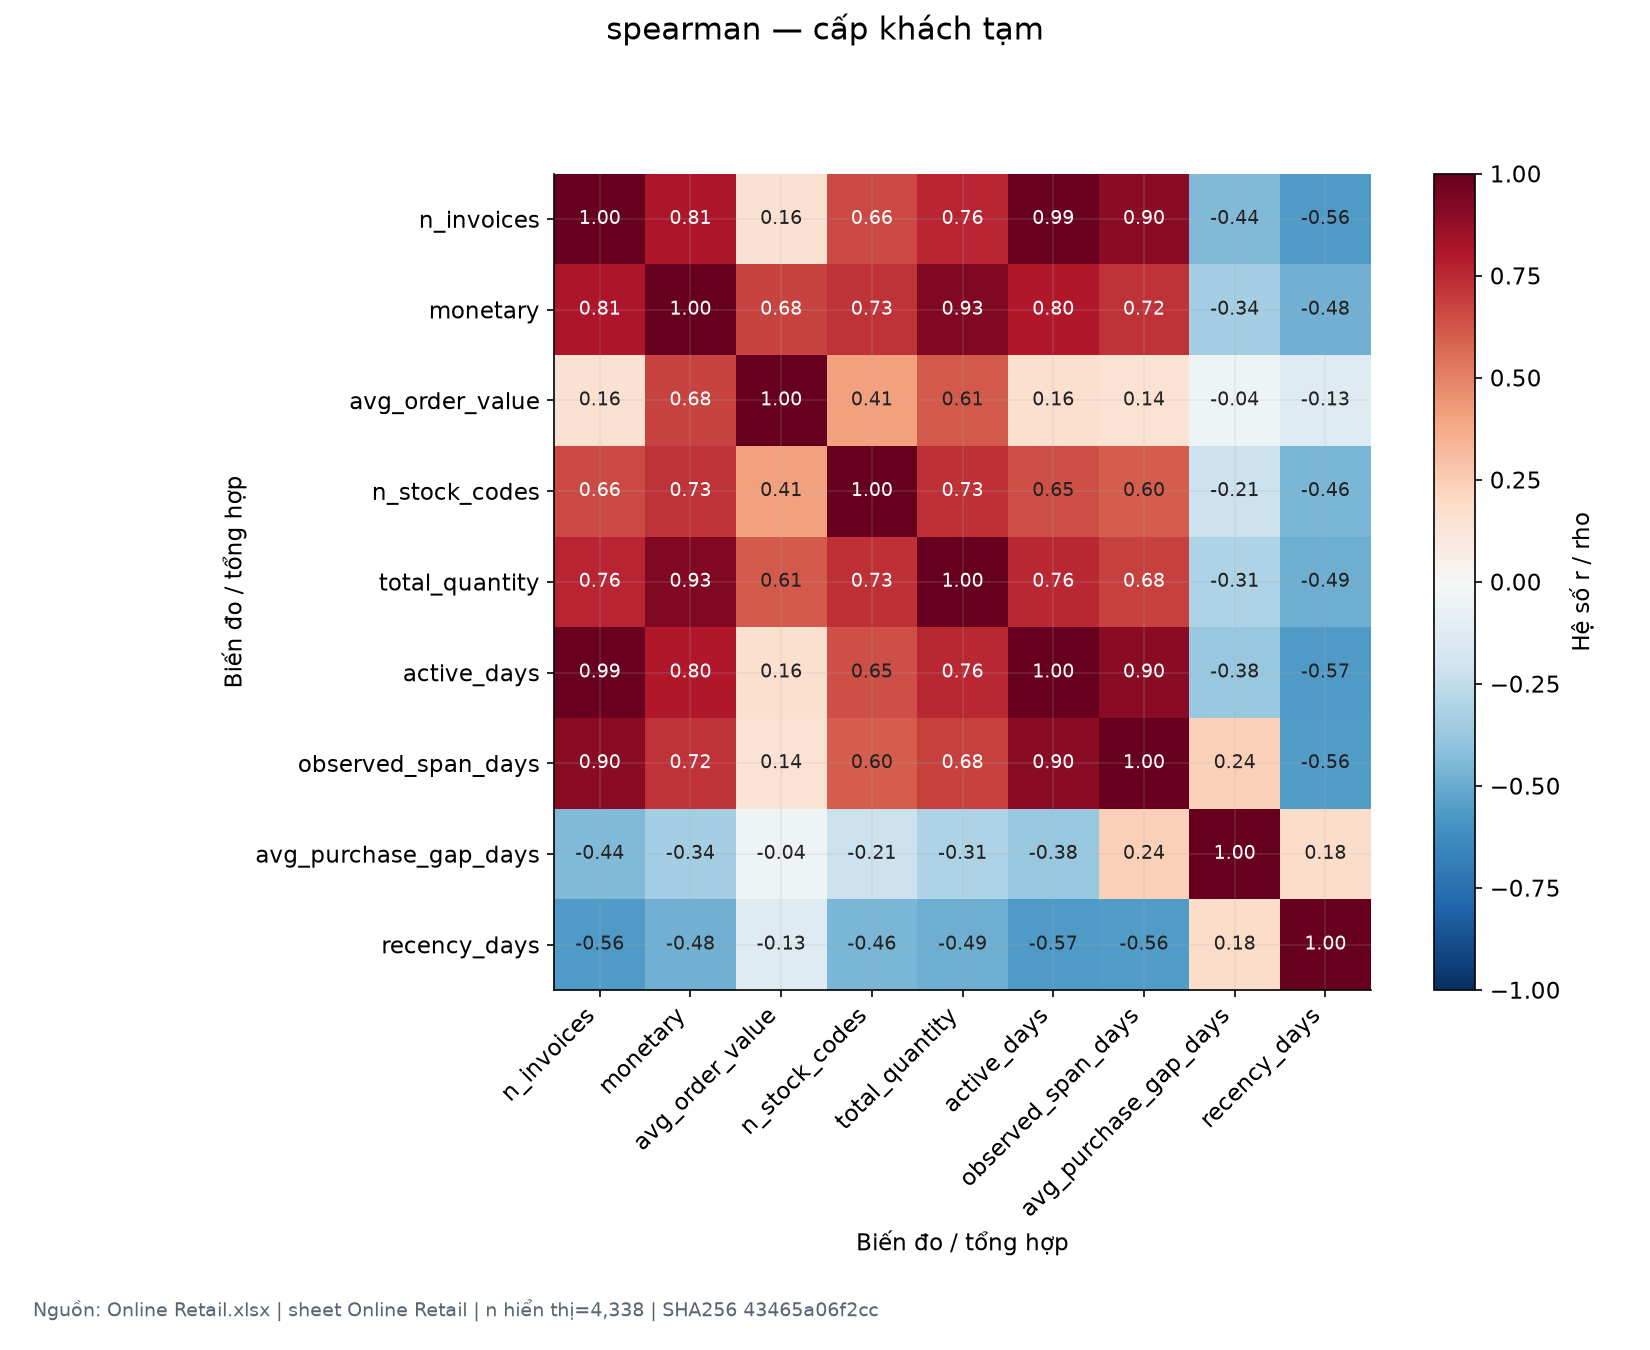

**Phạm vi:** InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean. Toàn bộ khách, hữu hạn theo cặp.

**Quan sát:** Pearson mô tả tuyến tính; Spearman mô tả đơn điệu theo hạng, nhạy khác nhau với cực trị.

**Bằng chứng:** n_invoices–monetary: n=4,338, Pearson=0.5536, Spearman=0.8075.

**Ý nghĩa:** Chọn biến theo ý nghĩa và độ trùng thông tin, không tự loại chỉ vì hệ số cao.

**Giới hạn / câu hỏi tiếp:** Pairwise finite deletion, min_periods=3; không impute và không lấy mẫu ma trận. IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc công thức; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_customer_spearman (T36), correlation_variable_audit (T41), aggregation_formulas (T38)

In [51]:
show_figure("correlation_customer_spearman")

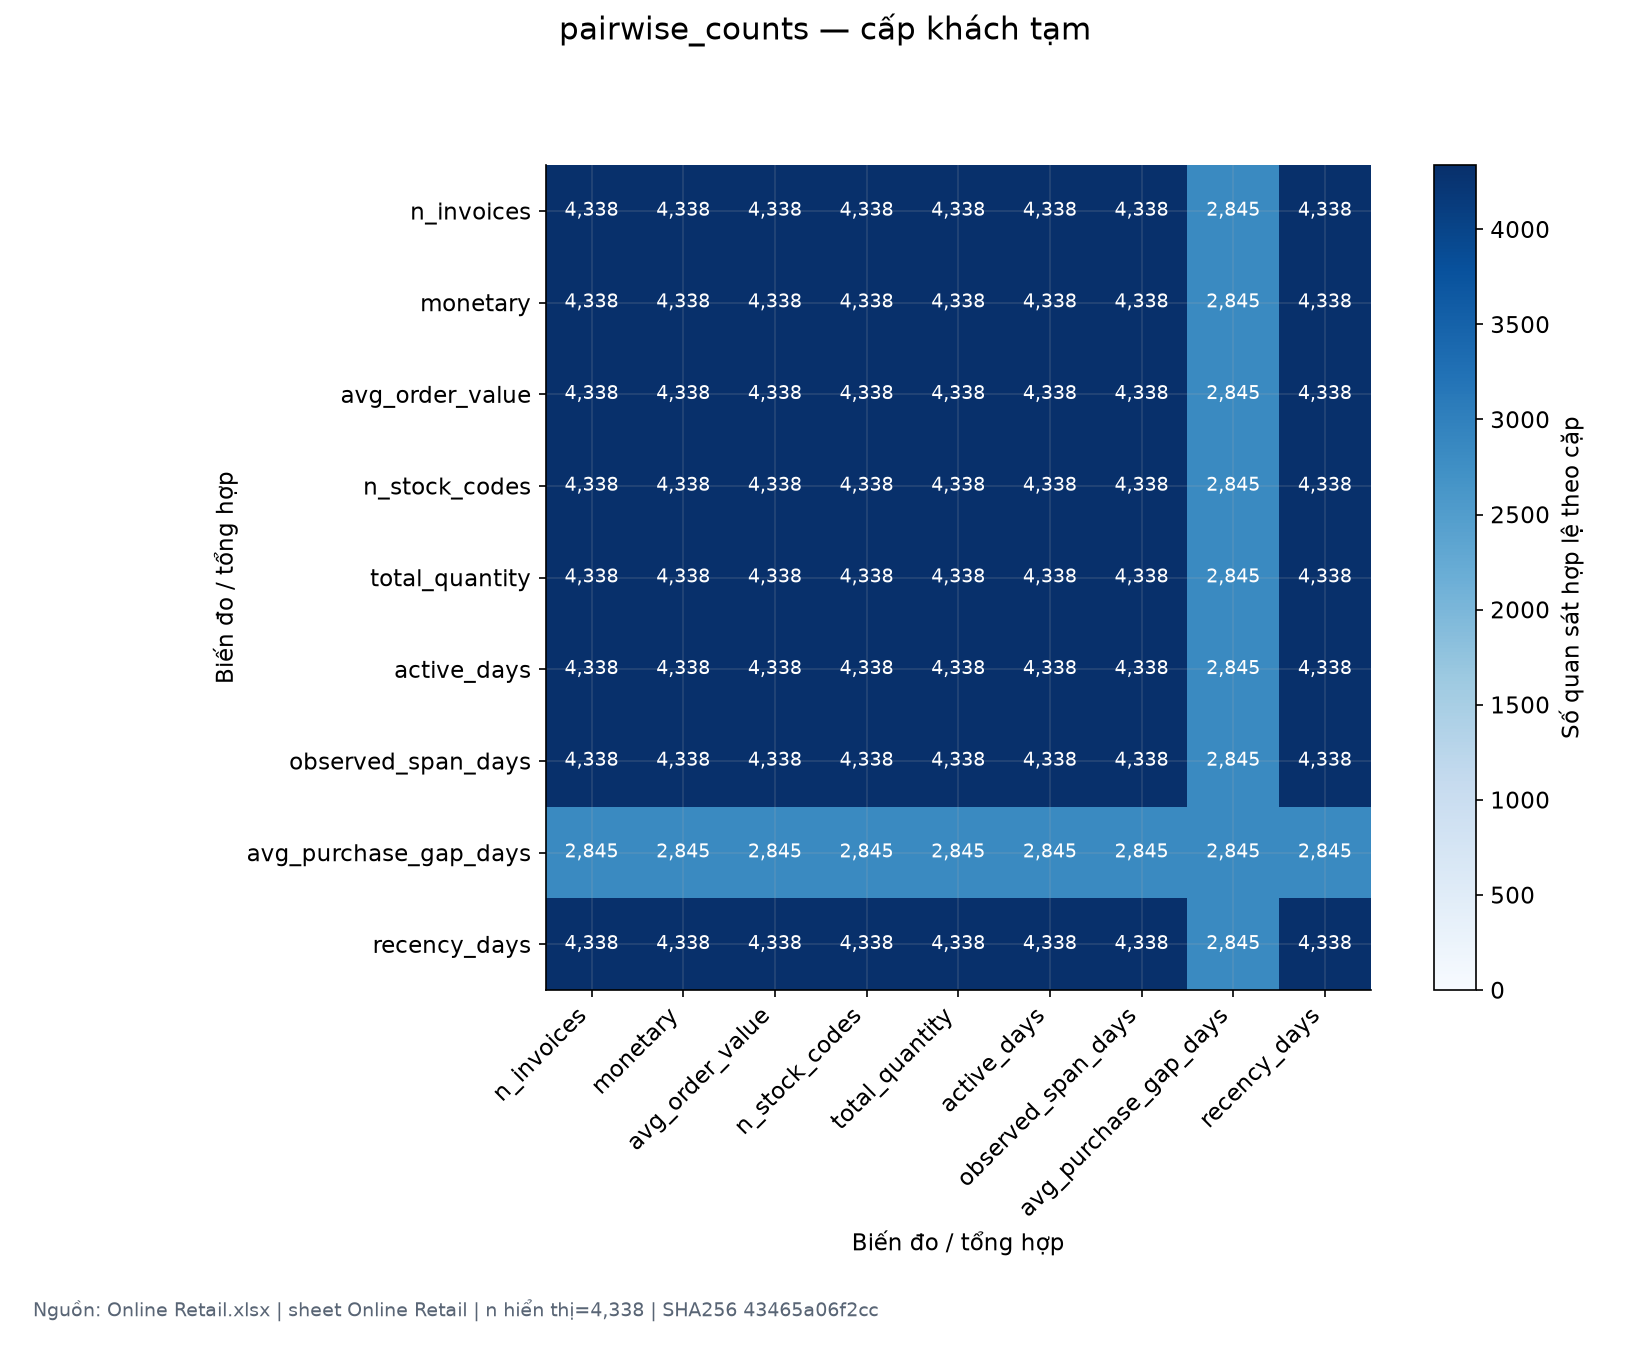

**Phạm vi:** InvoiceNo và CustomerID có mã, InvoiceDate hợp lệ; không có tiền tố C; Quantity > 0 và UnitPrice > 0, cả hai hữu hạn. Giữ nguyên dòng trùng và mã dịch vụ; chỉ là phạm vi khảo sát, chưa phải quy tắc clean. Toàn bộ khách, hữu hạn theo cặp.

**Quan sát:** Số cặp hợp lệ có thể khác nhau; không điền 0 cho dữ liệu chưa xác định.

**Bằng chứng:** n theo cặp từ 2,845 đến 4,338; gap thiếu ở 1,493 khách một đơn.

**Ý nghĩa:** Chọn biến theo ý nghĩa và độ trùng thông tin, không tự loại chỉ vì hệ số cao.

**Giới hạn / câu hỏi tiếp:** Pairwise finite deletion, min_periods=3; không impute và không lấy mẫu ma trận. IDs bị loại. SignedLineValue=Q×P và AOV=M/F có phụ thuộc công thức; tương quan không chứng minh nhân quả.

Bảng bằng chứng trong [workbook](../../experiments/eda_raw_moi/ket_qua_eda.xlsx): correlations_customer_pairwise_counts (T37), correlation_variable_audit (T41), aggregation_formulas (T38)

In [52]:
show_figure("correlation_customer_pairwise_counts")

In [53]:
show_table("correlations_customer_pairwise_counts", limit=20)

**correlations_customer_pairwise_counts** — 9 dòng × 9 cột; sheet T37 trong workbook kết quả.

,n_invoices,monetary,avg_order_value,n_stock_codes,total_quantity,active_days,observed_span_days,avg_purchase_gap_days,recency_days
n_invoices,4338,4338,4338,4338,4338,4338,4338,2845,4338
monetary,4338,4338,4338,4338,4338,4338,4338,2845,4338
avg_order_value,4338,4338,4338,4338,4338,4338,4338,2845,4338
n_stock_codes,4338,4338,4338,4338,4338,4338,4338,2845,4338
total_quantity,4338,4338,4338,4338,4338,4338,4338,2845,4338
active_days,4338,4338,4338,4338,4338,4338,4338,2845,4338
observed_span_days,4338,4338,4338,4338,4338,4338,4338,2845,4338
avg_purchase_gap_days,2845,2845,2845,2845,2845,2845,2845,2845,2845
recency_days,4338,4338,4338,4338,4338,4338,4338,2845,4338


## 8. Phương án sau EDA

Xem [đề xuất sau EDA](../../reports/de_xuat_sau_eda.md): các hướng data cleaning, encoding,
scaling và feature engineering kèm ưu/nhược, ảnh hưởng, bằng chứng và câu hỏi chờ thống nhất.
Thứ tự đề xuất: đặc trưng hành vi thủ công → RFM → ba hướng chỉ thủ công / chỉ RFM / kết hợp.

Các quyết định còn chờ nhóm: thiếu mã khách/mô tả; định nghĩa trùng; ghép hủy/trả;
giá 0/âm; mã dịch vụ; ngoại lệ/khách mua sỉ; cửa sổ quan sát và công thức hành vi;
danh mục/encoding; scaling; bộ biến và kiểm soát thông tin trùng.
Không phương án nào được áp dụng vào pipeline ở notebook này.

## 9. Xuất kết quả và kiểm tra

Xuất thống kê/mẫu kiểm tra, danh mục hình/bảng và metadata vào một workbook, cùng báo cáo từ **cùng bảng trong bộ nhớ**.
Không xuất giao dịch đã làm sạch hay ma trận feature khách. Kiểm tra checksum raw, mã production,
processed và khảo sát Form 2; kiểm tra tổng, gap/AOV và cặp tương quan bằng scipy.

In [54]:
metadata = export_results(analysis)
display(Markdown(f"**Đã xuất {metadata['figure_count']} hình và {metadata['table_count']} bảng trong một workbook.**"))
display(metadata["checks"])
display(Markdown("[Báo cáo EDA](../../reports/bao_cao_eda_raw_moi.md) · "
                 "[Workbook bảng, metadata và danh mục hình](../../experiments/eda_raw_moi/ket_qua_eda.xlsx)"))

**Đã xuất 21 hình và 41 bảng trong một workbook.**

{'raw_unchanged': True,
 'protected_files_unchanged': True,
 'aggregation_reconciled': True,
 'correlations_checked_against_scipy': True,
 'monthly_and_categorical_totals_reconciled': True,
 'figures_expected': 21,
 'figures_created': 21}

[Báo cáo EDA](../../reports/bao_cao_eda_raw_moi.md) · [Workbook bảng, metadata và danh mục hình](../../experiments/eda_raw_moi/ket_qua_eda.xlsx)

### Giới hạn khi diễn giải

Cửa sổ một nhà bán lẻ hữu hạn, chưa biết múi giờ, chưa ghép chứng từ trả với mua và chưa xác nhận mã hàng thực.
Không quan sát được tuổi khách thật hay hoạt động trước/sau raw. Khách một đơn giữ gap thiếu.
Số liệu có dấu chưa là doanh thu thuần; tương quan không chứng minh nhân quả hoặc khả năng dự báo.